<a href="https://colab.research.google.com/github/fanniii03/Heart-Disease-Health-Indicators-Dataset/blob/main/BevAdatProjekt.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Osztályegyensúly a szívbetegség-felmérésben

## Kutatási kérdés

Mennyire különíthetők el a kérdőív alapján azok,
akik korábbi koszorúér-betegségről vagy
szívinfarktusról számoltak be?

## A projekt célja

A BRFSS 2015 kérdőíves adatkészletének elemzése,
az osztályegyensúly hiányának vizsgálata,
valamint gépi tanulási modellek összehasonlítása.

A projekt során logisztikus regressziót és
gyakoriságon alapuló alapmodellt alkalmazunk.


2. Szükséges könyvtárak importálása

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

# Modellértékelés
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    fbeta_score,
    balanced_accuracy_score,
    confusion_matrix,
    classification_report,
    average_precision_score,
    precision_recall_curve,
    auc
)

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

# Reprodukálhatóság
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

sns.set_theme(style="whitegrid")

OUTPUT_DIR = Path("eredmenyek")
OUTPUT_DIR.mkdir(exist_ok=True)

print("A könyvtárak sikeresen betöltve.")
print("Random state:", RANDOM_STATE)
print("Eredmények mappája:", OUTPUT_DIR.resolve())

A könyvtárak sikeresen betöltve.
Random state: 42
Eredmények mappája: /content/eredmenyek


### 3. CSV-fájl feltöltése Google Colabban
Magyarázat:

A saját számítógépéről fogja kiválasztani a CSV-fájlt.

Nem rögzítünk konkrét fájlnevet, így a notebook más néven elmentett változattal is működik.

A fájlbeolvasásnál automatikusan felismerjük a tagolást, és ellenőrizzük, hogy a 22 elvárt oszlop rendelkezésre áll-e.

In [3]:
from google.colab import files

print("Válaszd ki a Heart Disease Health Indicators CSV-fájlt!")

uploaded = files.upload()

if len(uploaded) == 0:
    raise ValueError("Nem történt fájlfeltöltés!")

# A feltöltött fájl neve
file_name = next(iter(uploaded))

if not file_name.lower().endswith(".csv"):
    raise ValueError("A feltöltött fájlnak CSV formátumúnak kell lennie!")

print("\nSikeres feltöltés:", file_name)

Válaszd ki a Heart Disease Health Indicators CSV-fájlt!


Saving heart_disease_health_indicators_BRFSS2015.csv to heart_disease_health_indicators_BRFSS2015 (1).csv

Sikeres feltöltés: heart_disease_health_indicators_BRFSS2015 (1).csv


### 4. Adatok beolvasása és szerkezeti ellenőrzése
Magyarázat:

A következő lépésben beolvassuk az adatállományt pandas DataFrame formátumba.

A sep=None és engine='python' beállítás megpróbálja automatikusan felismerni az elválasztó karaktert. A feltöltött állomány esetében ez pontosvessző.

A projekt csak akkor folytatódhat, ha az elvárt 22 változó megtalálható.

In [4]:
# CSV automatikus elválasztófelismeréssel
df = pd.read_csv(
    file_name,
    sep=None,
    engine="python"
)

# Elvárt oszlopok
expected_columns = [
    "HeartDiseaseorAttack",
    "HighBP",
    "HighChol",
    "CholCheck",
    "BMI",
    "Smoker",
    "Stroke",
    "Diabetes",
    "PhysActivity",
    "Fruits",
    "Veggies",
    "HvyAlcoholConsump",
    "AnyHealthcare",
    "NoDocbcCost",
    "GenHlth",
    "MentHlth",
    "PhysHlth",
    "DiffWalk",
    "Sex",
    "Age",
    "Education",
    "Income"
]

# Szerkezeti ellenőrzés
missing_columns = [
    col for col in expected_columns
    if col not in df.columns
]

extra_columns = [
    col for col in df.columns
    if col not in expected_columns
]

print("Adatállomány mérete:", df.shape)
print("Oszlopok száma:", len(df.columns))
print("Hiányzó elvárt oszlopok:", missing_columns)
print("Többlet oszlopok:", extra_columns)

if len(df.columns) != 22 or missing_columns or extra_columns:
    raise ValueError(
        "Az adatállomány szerkezete nem felel meg "
        "a dokumentált 22 oszlopos formátumnak. "
        "A modellezés nem folytatható."
    )

# A dokumentált sorrend megtartása
df = df[expected_columns].copy()

print("\nA megfelelő adatállomány sikeresen betöltve!")

Adatállomány mérete: (253680, 22)
Oszlopok száma: 22
Hiányzó elvárt oszlopok: []
Többlet oszlopok: []

A megfelelő adatállomány sikeresen betöltve!


### 5. Az adatállomány első és utolsó rekordjai
Magyarázat:

Megnézzük az első és utolsó öt rekordot. Ez segít ellenőrizni, hogy a beolvasás megfelelően történt-e, és az oszlopok valóban külön változóként jelennek-e meg.

In [5]:
print("ELSŐ ÖT REKORD")
display(df.head())

print("\nUTOLSÓ ÖT REKORD")
display(df.tail())

print("\nADATÁLLOMÁNY MÉRETE")
print(f"Sorok száma: {df.shape[0]:,}")
print(f"Oszlopok száma: {df.shape[1]}")

ELSŐ ÖT REKORD


,HeartDiseaseorAttack,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0000,1.0000,1.0000,1.0000,40.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,5.0000,18.0000,15.0000,1.0000,0.0000,9.0000,4.0000,3.0000
1,0.0000,0.0000,0.0000,0.0000,25.0000,1.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,1.0000,3.0000,0.0000,0.0000,0.0000,0.0000,7.0000,6.0000,1.0000
2,0.0000,1.0000,1.0000,1.0000,28.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,1.0000,1.0000,5.0000,30.0000,30.0000,1.0000,0.0000,9.0000,4.0000,8.0000
3,0.0000,1.0000,0.0000,1.0000,27.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,11.0000,3.0000,6.0000
4,0.0000,1.0000,1.0000,1.0000,24.0000,0.0000,0.0000,0.0000,1.0000,1.0000,1.0000,0.0000,1.0000,0.0000,2.0000,3.0000,0.0000,0.0000,0.0000,11.0000,5.0000,4.0000



UTOLSÓ ÖT REKORD


,HeartDiseaseorAttack,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,Diabetes,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
253675,0.0000,1.0000,1.0000,1.0000,45.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000,3.0000,0.0000,5.0000,0.0000,1.0000,5.0000,6.0000,7.0000
253676,0.0000,1.0000,1.0000,1.0000,18.0000,0.0000,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,4.0000,0.0000,0.0000,1.0000,0.0000,11.0000,2.0000,4.0000
253677,0.0000,0.0000,0.0000,1.0000,28.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.0000,2.0000,5.0000,2.0000
253678,0.0000,1.0000,0.0000,1.0000,23.0000,0.0000,0.0000,0.0000,0.0000,1.0000,1.0000,0.0000,1.0000,0.0000,3.0000,0.0000,0.0000,0.0000,1.0000,7.0000,5.0000,1.0000
253679,1.0000,1.0000,1.0000,1.0000,25.0000,0.0000,0.0000,2.0000,1.0000,1.0000,0.0000,0.0000,1.0000,0.0000,2.0000,0.0000,0.0000,0.0000,0.0000,9.0000,6.0000,2.0000



ADATÁLLOMÁNY MÉRETE
Sorok száma: 253,680
Oszlopok száma: 22


### 6. Adattípusok és alapvető adatminőség-ellenőrzés
Magyarázat:

Ebben a szakaszban ellenőrizzük:
- az egyes változók adattípusát;
- a hiányzó értékeket;
- a teljesen egyező sorokat;
- az egyedi értékek számát;
- a numerikus változók alapstatisztikáit.
A hiányzó adatokat nem töröljük, hanem a későbbi modellezés során kezeljük.

A teljesen egyező sorokat sem távolítjuk el, mivel egyedi válaszadói azonosító hiányában nem állapítható meg, hogy valódi ismételt rekordokról vagy különböző, azonos válaszokat adó személyekről van-e szó.

In [6]:
# Adattípusok
print("ADATTÍPUSOK")
display(df.dtypes.to_frame("Adattípus"))

# Hiányzó értékek
missing_table = pd.DataFrame({
    "Hiányzó értékek": df.isna().sum(),
    "Hiányzó arány (%)": df.isna().mean() * 100
})

print("\nHIÁNYZÓ ÉRTÉKEK")
display(missing_table)

# Duplikált sorok
duplicate_count = df.duplicated().sum()
duplicate_percentage = duplicate_count / len(df) * 100

print("\nDUPLIKÁCIÓK")
print("Teljesen egyező sorok:", duplicate_count)
print(f"Arányuk: {duplicate_percentage:.2f}%")

# Egyedi értékek száma
print("\nEGYEDI ÉRTÉKEK SZÁMA")
display(df.nunique().to_frame("Egyedi értékek"))

# Leíró statisztikák
print("\nLEÍRÓ STATISZTIKÁK")
display(df.describe().T)

ADATTÍPUSOK


,Adattípus
HeartDiseaseorAttack,float64
HighBP,float64
HighChol,float64
CholCheck,float64
BMI,float64
Smoker,float64
Stroke,float64
Diabetes,float64
PhysActivity,float64
Fruits,float64



HIÁNYZÓ ÉRTÉKEK


,Hiányzó értékek,Hiányzó arány (%)
HeartDiseaseorAttack,0,0.0000
HighBP,0,0.0000
HighChol,0,0.0000
CholCheck,0,0.0000
BMI,0,0.0000
Smoker,0,0.0000
Stroke,0,0.0000
Diabetes,0,0.0000
PhysActivity,0,0.0000
Fruits,0,0.0000



DUPLIKÁCIÓK
Teljesen egyező sorok: 23899
Arányuk: 9.42%

EGYEDI ÉRTÉKEK SZÁMA


,Egyedi értékek
HeartDiseaseorAttack,2
HighBP,2
HighChol,2
CholCheck,2
BMI,84
Smoker,2
Stroke,2
Diabetes,3
PhysActivity,2
Fruits,2



LEÍRÓ STATISZTIKÁK


,count,mean,std,min,25%,50%,75%,max
HeartDiseaseorAttack,253680.0000,0.0942,0.2921,0.0000,0.0000,0.0000,0.0000,1.0000
HighBP,253680.0000,0.4290,0.4949,0.0000,0.0000,0.0000,1.0000,1.0000
HighChol,253680.0000,0.4241,0.4942,0.0000,0.0000,0.0000,1.0000,1.0000
CholCheck,253680.0000,0.9627,0.1896,0.0000,1.0000,1.0000,1.0000,1.0000
BMI,253680.0000,28.3824,6.6087,12.0000,24.0000,27.0000,31.0000,98.0000
Smoker,253680.0000,0.4432,0.4968,0.0000,0.0000,0.0000,1.0000,1.0000
Stroke,253680.0000,0.0406,0.1973,0.0000,0.0000,0.0000,0.0000,1.0000
Diabetes,253680.0000,0.2969,0.6982,0.0000,0.0000,0.0000,0.0000,2.0000
PhysActivity,253680.0000,0.7565,0.4292,0.0000,1.0000,1.0000,1.0000,1.0000
Fruits,253680.0000,0.6343,0.4816,0.0000,0.0000,1.0000,1.0000,1.0000


### 7. Változók tényleges értéktartományának ellenőrzése
Magyarázat:

A változókat nem elegendő a nevük alapján értelmezni. Ellenőriznünk kell, hogy milyen értékek szerepelnek ténylegesen az adatállományban.

A dokumentált értéktartományoktól eltérő értékeket nem fogadjuk el automatikusan.

A következő táblázatban minden változó egyedi értékeit megjelenítjük.

In [7]:
for column in df.columns:
    print(f"\n{column}")
    print("Egyedi értékek:",
          sorted(df[column].dropna().unique().tolist()))


HeartDiseaseorAttack
Egyedi értékek: [0.0, 1.0]

HighBP
Egyedi értékek: [0.0, 1.0]

HighChol
Egyedi értékek: [0.0, 1.0]

CholCheck
Egyedi értékek: [0.0, 1.0]

BMI
Egyedi értékek: [12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19.0, 20.0, 21.0, 22.0, 23.0, 24.0, 25.0, 26.0, 27.0, 28.0, 29.0, 30.0, 31.0, 32.0, 33.0, 34.0, 35.0, 36.0, 37.0, 38.0, 39.0, 40.0, 41.0, 42.0, 43.0, 44.0, 45.0, 46.0, 47.0, 48.0, 49.0, 50.0, 51.0, 52.0, 53.0, 54.0, 55.0, 56.0, 57.0, 58.0, 59.0, 60.0, 61.0, 62.0, 63.0, 64.0, 65.0, 66.0, 67.0, 68.0, 69.0, 70.0, 71.0, 72.0, 73.0, 74.0, 75.0, 76.0, 77.0, 78.0, 79.0, 80.0, 81.0, 82.0, 83.0, 84.0, 85.0, 86.0, 87.0, 88.0, 89.0, 90.0, 91.0, 92.0, 95.0, 96.0, 98.0]

Smoker
Egyedi értékek: [0.0, 1.0]

Stroke
Egyedi értékek: [0.0, 1.0]

Diabetes
Egyedi értékek: [0.0, 1.0, 2.0]

PhysActivity
Egyedi értékek: [0.0, 1.0]

Fruits
Egyedi értékek: [0.0, 1.0]

Veggies
Egyedi értékek: [0.0, 1.0]

HvyAlcoholConsump
Egyedi értékek: [0.0, 1.0]

AnyHealthcare
Egyedi értékek: [0.0, 1.0]

No

### 8. A változók dokumentált jelentése és kódolása
Magyarázat

A Kaggle-adatkészletben szereplő változókat a feladatleírás és a CDC dokumentációja alapján értelmezzük.

Fontos különbség, hogy a Kaggle-adatkészlet már átalakított változat. Például:
- Sex: 0 = nő, 1 = férfi.
- Diabetes: 0 = nincs cukorbetegség vagy csak terhesség alatti cukorbetegség, 1 = prediabétesz, 2 = cukorbetegség.
- GenHlth: 1–5 közötti egészségi állapot.
- Age: 1–13 közötti korcsoport.
Az eredeti CDC-kérdőívben egyes változók kódolása ettől eltérhet. A CDC eredeti adatleírását ezért háttérforrásként, nem pedig a Kaggle-adatállomány közvetlen értékkészleteként használjuk.

In [8]:
variable_descriptions = {
    "HeartDiseaseorAttack": "Korábbi koszorúér-betegség vagy szívinfarktus",
    "HighBP": "Magas vérnyomás",
    "HighChol": "Magas koleszterinszint",
    "CholCheck": "Koleszterinszint ellenőrzése az elmúlt öt évben",
    "BMI": "Testtömegindex",
    "Smoker": "Legalább 100 cigaretta elszívása élete során",
    "Stroke": "Korábbi stroke",
    "Diabetes": "Cukorbetegség kategóriája",
    "PhysActivity": "Fizikai aktivitás",
    "Fruits": "Napi legalább egyszeri gyümölcsfogyasztás",
    "Veggies": "Napi legalább egyszeri zöldségfogyasztás",
    "HvyAlcoholConsump": "Nagymértékű alkoholfogyasztás",
    "AnyHealthcare": "Egészségügyi ellátási fedezet",
    "NoDocbcCost": "Költség miatt elmaradt orvosi vizsgálat",
    "GenHlth": "Általános egészségi állapot",
    "MentHlth": "Mentális egészségi problémával érintett napok",
    "PhysHlth": "Fizikai egészségi problémával érintett napok",
    "DiffWalk": "Nehézség járás vagy lépcsőzés közben",
    "Sex": "Nem a Kaggle-adatkészlet kódolása szerint",
    "Age": "Korcsoport",
    "Education": "Iskolai végzettség",
    "Income": "Háztartási jövedelmi kategória"
}

binary_variables = [
    "HighBP", "HighChol", "CholCheck", "Smoker",
    "Stroke", "PhysActivity", "Fruits", "Veggies",
    "HvyAlcoholConsump", "AnyHealthcare",
    "NoDocbcCost", "DiffWalk", "Sex"
]

numeric_variables = [
    "BMI", "MentHlth", "PhysHlth"
]

categorical_variables = [
    "Diabetes", "GenHlth", "Age", "Education", "Income"
]

# Dokumentált értékkészletek
allowed_values = {
    "HeartDiseaseorAttack": [0, 1],
    **{col: [0, 1] for col in binary_variables},
    "Diabetes": [0, 1, 2],
    "GenHlth": [1, 2, 3, 4, 5],
    "Age": list(range(1, 14)),
    "Education": list(range(1, 7)),
    "Income": list(range(1, 9)),
    "BMI": None,
    "MentHlth": list(range(0, 31)),
    "PhysHlth": list(range(0, 31))
}

documentation_table = []

for col in df.columns:
    actual = sorted(df[col].dropna().unique().tolist())
    allowed = allowed_values[col]

    documentation_table.append({
        "Változó": col,
        "Jelentés": variable_descriptions[col],
        "Tényleges értékek": actual,
        "Dokumentált értékek": (
            "Numerikus, külön ellenőrizendő"
            if allowed is None else allowed
        ),
        "Változótípus": (
            "Bináris" if col in binary_variables
            else "Numerikus" if col in numeric_variables
            else "Sorrendi/kategorikus"
        ),
        "Eltérés": (
            "Nincs"
            if allowed is None or set(actual).issubset(set(allowed))
            else "ELLENŐRIZENDŐ"
        )
    })

documentation_df = pd.DataFrame(documentation_table)

display(documentation_df)

,Változó,Jelentés,Tényleges értékek,Dokumentált értékek,Változótípus,Eltérés
0,HeartDiseaseorAttack,Korábbi koszorúér-betegség vagy szívinfarktus,"[0.0, 1.0]","[0, 1]",Sorrendi/kategorikus,Nincs
1,HighBP,Magas vérnyomás,"[0.0, 1.0]","[0, 1]",Bináris,Nincs
2,HighChol,Magas koleszterinszint,"[0.0, 1.0]","[0, 1]",Bináris,Nincs
3,CholCheck,Koleszterinszint ellenőrzése az elmúlt öt évben,"[0.0, 1.0]","[0, 1]",Bináris,Nincs
4,BMI,Testtömegindex,"[12.0, 13.0, 14.0, 15.0, 16.0, 17.0, 18.0, 19....","Numerikus, külön ellenőrizendő",Numerikus,Nincs
5,Smoker,Legalább 100 cigaretta elszívása élete során,"[0.0, 1.0]","[0, 1]",Bináris,Nincs
6,Stroke,Korábbi stroke,"[0.0, 1.0]","[0, 1]",Bináris,Nincs
7,Diabetes,Cukorbetegség kategóriája,"[0.0, 1.0, 2.0]","[0, 1, 2]",Sorrendi/kategorikus,Nincs
8,PhysActivity,Fizikai aktivitás,"[0.0, 1.0]","[0, 1]",Bináris,Nincs
9,Fruits,Napi legalább egyszeri gyümölcsfogyasztás,"[0.0, 1.0]","[0, 1]",Bináris,Nincs


Külön BMI-ellenőrzés:

A BMI változó esetében a dokumentáció nem határoz meg szűk, minden válaszadóra kötelező értéktartományt. Ezért a tényleges minimumot, maximumot és az esetleges szélsőértékeket vizsgáljuk.

In [9]:
print("BMI minimum:", df["BMI"].min())
print("BMI maximum:", df["BMI"].max())
print("BMI medián:", df["BMI"].median())

display(
    df["BMI"].describe().to_frame("BMI statisztikák")
)

BMI minimum: 12.0
BMI maximum: 98.0
BMI medián: 27.0


,BMI statisztikák
count,253680.0000
mean,28.3824
std,6.6087
min,12.0000
25%,24.0000
50%,27.0000
75%,31.0000
max,98.0000


### 9. Az adatállomány alapvető vizualizációi
Magyarázat

A modellezés előtt grafikonokon is megvizsgáljuk az adatokat.

Elsőként a hiányzó értékeket és a numerikus változók eloszlását mutatjuk be.

Minden fontos grafikont PNG formátumban mentünk az eredmenyek mappába.

9.1. Hiányzó értékek grafikonja

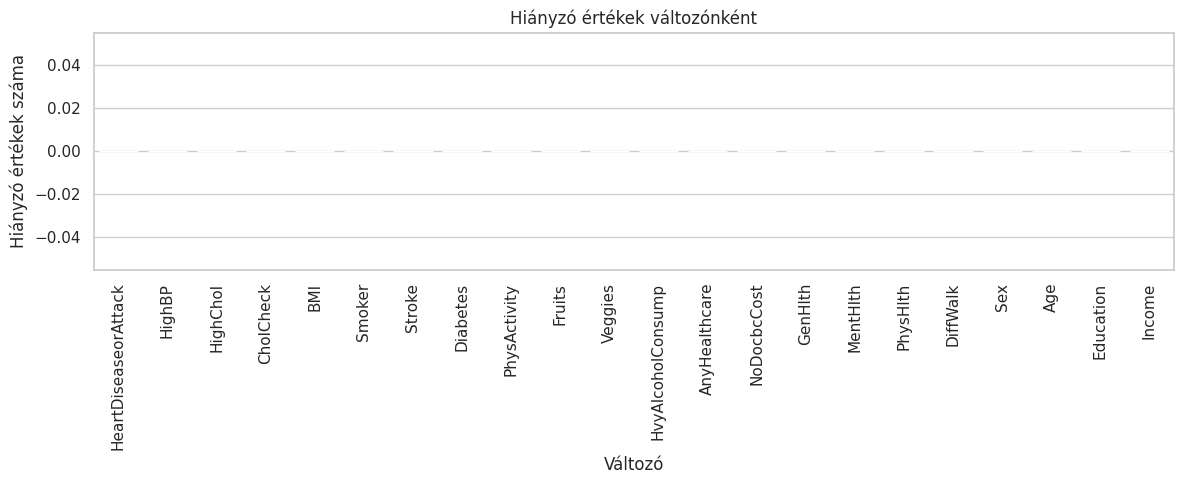

In [10]:
plt.figure(figsize=(12, 5))

missing_counts = df.isna().sum()

sns.barplot(
    x=missing_counts.index,
    y=missing_counts.values
)

plt.title("Hiányzó értékek változónként")
plt.xlabel("Változó")
plt.ylabel("Hiányzó értékek száma")
plt.xticks(rotation=90)

plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "hianyzo_ertekek.png",
    dpi=200
)

plt.show()

9.2. BMI eloszlása

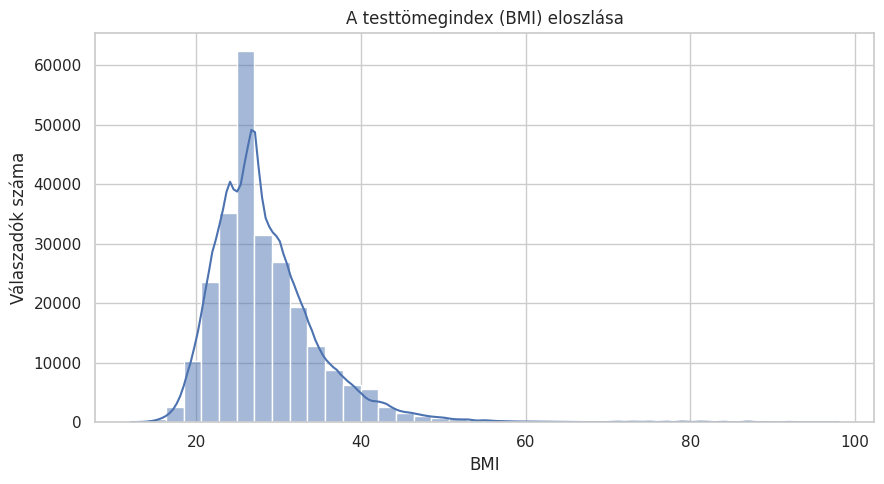

In [11]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="BMI",
    bins=40,
    kde=True
)

plt.title("A testtömegindex (BMI) eloszlása")
plt.xlabel("BMI")
plt.ylabel("Válaszadók száma")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "bmi_eloszlas.png", dpi=200)
plt.show()

9.3. Mentális és fizikai egészségi problémával érintett napok

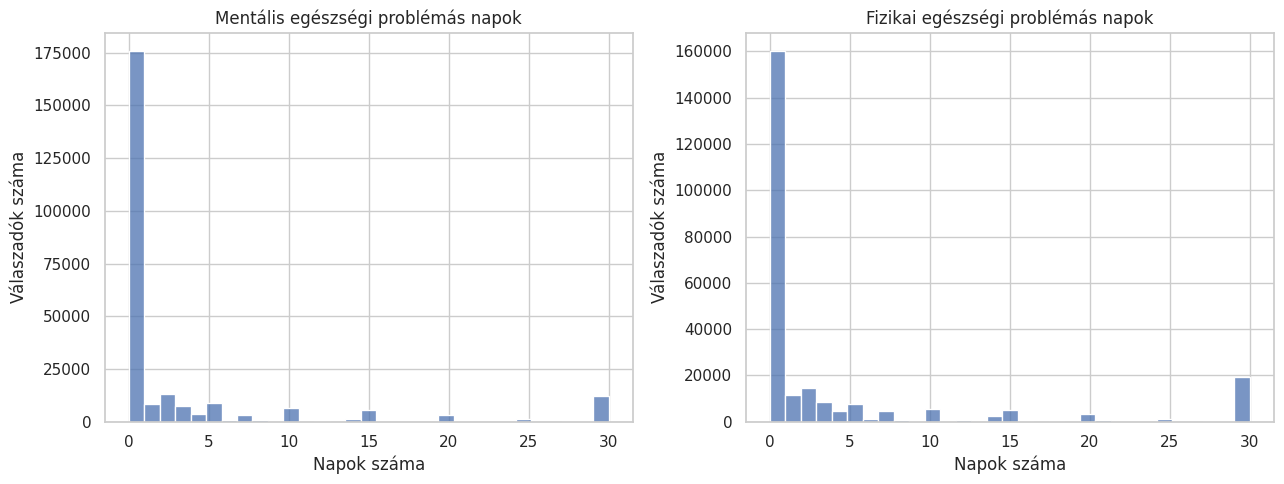

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.histplot(
    df["MentHlth"],
    bins=31,
    ax=axes[0]
)

axes[0].set_title("Mentális egészségi problémás napok")
axes[0].set_xlabel("Napok száma")
axes[0].set_ylabel("Válaszadók száma")

sns.histplot(
    df["PhysHlth"],
    bins=31,
    ax=axes[1]
)

axes[1].set_title("Fizikai egészségi problémás napok")
axes[1].set_xlabel("Napok száma")
axes[1].set_ylabel("Válaszadók száma")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "egeszsegi_napok.png", dpi=200)
plt.show()

9.4. Korcsoportok gyakorisága

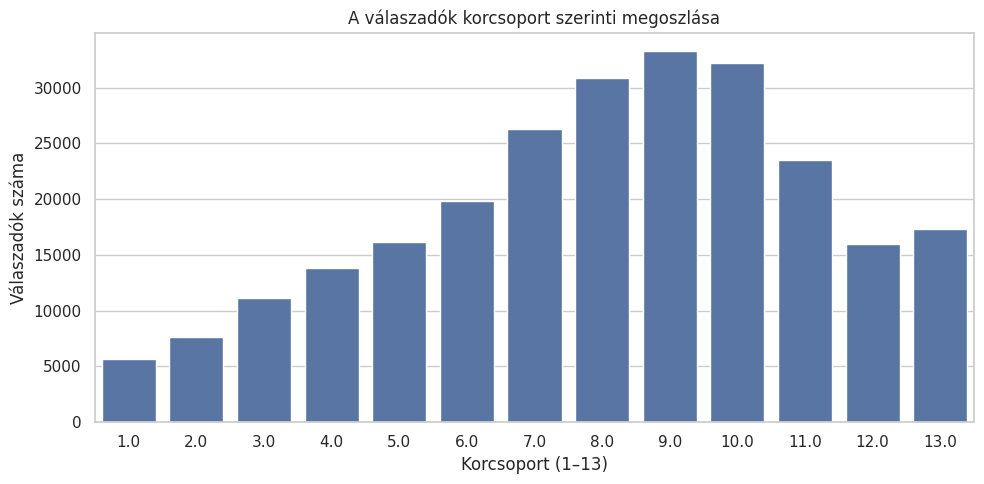

In [13]:
plt.figure(figsize=(10, 5))

age_counts = df["Age"].value_counts().sort_index()

sns.barplot(
    x=age_counts.index,
    y=age_counts.values
)

plt.title("A válaszadók korcsoport szerinti megoszlása")
plt.xlabel("Korcsoport (1–13)")
plt.ylabel("Válaszadók száma")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "korcsoportok.png", dpi=200)
plt.show()

9.5. Általános egészségi állapot

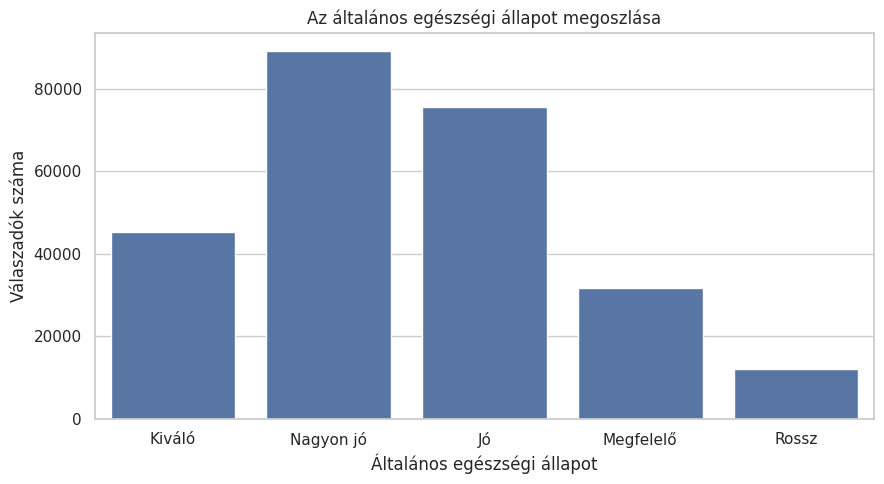

In [14]:
health_counts = df["GenHlth"].value_counts().sort_index()

health_labels = {
    1: "Kiváló",
    2: "Nagyon jó",
    3: "Jó",
    4: "Megfelelő",
    5: "Rossz"
}

plt.figure(figsize=(9, 5))

sns.barplot(
    x=[health_labels[i] for i in health_counts.index],
    y=health_counts.values
)

plt.title("Az általános egészségi állapot megoszlása")
plt.xlabel("Általános egészségi állapot")
plt.ylabel("Válaszadók száma")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "altalanos_egeszseg.png", dpi=200)
plt.show()

### 10. A célváltozó és az osztályegyensúly vizsgálata
Magyarázat

Ez a kutatás egyik legfontosabb része.

A célváltozó két osztálya nem egyenlő arányban szerepel az adatokban.

A Kaggle dokumentációja szerint:
- 229 787 válaszadó nem számolt be korábbi szívbetegségről.
- 23 893 válaszadó beszámolt korábbi szívbetegségről.
Ez jelentős osztályegyensúly-hiányt jelent.
kaggle.com


Először kiszámítjuk a tényleges arányokat, majd meghatározzuk, hogy milyen accuracy értéket érne el egy olyan egyszerű modell, amely mindenkit a többségi osztályba sorol.

10.1. Gyakorisági és százalékos táblázat

In [15]:
target_counts = df["HeartDiseaseorAttack"].value_counts().sort_index()

target_percentages = (
    df["HeartDiseaseorAttack"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

class_distribution = pd.DataFrame({
    "Esetszám": target_counts,
    "Arány (%)": target_percentages
})

class_distribution.index = [
    "0 - Nem számolt be",
    "1 - Beszámolt"
]

display(class_distribution)

positive_count = target_counts.loc[1]
negative_count = target_counts.loc[0]

positive_rate = positive_count / len(df)
negative_rate = negative_count / len(df)

print(f"Negatív esetek: {negative_count:,}")
print(f"Pozitív esetek: {positive_count:,}")
print(f"Pozitív arány: {positive_rate * 100:.2f}%")
print(f"Negatív arány: {negative_rate * 100:.2f}%")
print(
    "Az osztályarányok különbsége:",
    f"{abs(negative_rate-positive_rate)*100:.2f} százalékpont"
)

,Esetszám,Arány (%)
0 - Nem számolt be,229787,90.5814
1 - Beszámolt,23893,9.4186


Negatív esetek: 229,787
Pozitív esetek: 23,893
Pozitív arány: 9.42%
Negatív arány: 90.58%
Az osztályarányok különbsége: 81.16 százalékpont


10.2. Osztályeloszlás grafikus megjelenítése

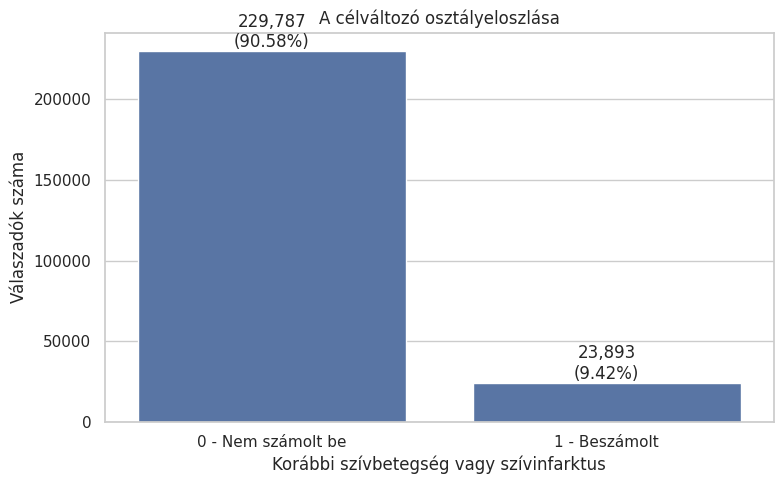

In [16]:
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    x=["0 - Nem számolt be", "1 - Beszámolt"],
    y=target_counts.values
)

plt.title("A célváltozó osztályeloszlása")
plt.xlabel("Korábbi szívbetegség vagy szívinfarktus")
plt.ylabel("Válaszadók száma")

for i, value in enumerate(target_counts.values):
    ax.text(
        i,
        value,
        f"{value:,}\n({value/len(df)*100:.2f}%)",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "osztalyeloszlas.png", dpi=200)
plt.show()

10.3. Többségi osztályra épülő alapmodell accuracy értéke

In [17]:
majority_accuracy = negative_count / len(df)

print(
    "Többségi osztályt választó modell accuracy értéke:",
    f"{majority_accuracy:.4f}"
)

print(
    f"Százalékosan: {majority_accuracy*100:.2f}%"
)

Többségi osztályt választó modell accuracy értéke: 0.9058
Százalékosan: 90.58%


Az accuracy önmagában félrevezető lehet. Egy olyan modell is magas összpontosságot érhet el, amely egyetlen pozitív esetet sem azonosít.

Ezért a továbbiakban különösen fontos lesz a Recall, az F2-score és az Average Precision vizsgálata.

### 11. A magyarázó változók és a célváltozó kapcsolata
Magyarázat

Ebben a szakaszban azt vizsgáljuk, hogy a különböző egészségügyi és demográfiai csoportokban milyen arányban fordulnak elő azok a válaszadók, akik korábbi szívbetegségről vagy szívinfarktusról számoltak be.

Nem elegendő az egyes csoportok elemszámát vizsgálni. A csoporton belüli pozitív arányt is ki kell számolni.

Például nem azt szeretnénk megtudni, hogy hány magas vérnyomással rendelkező válaszadó tartozik a pozitív osztályba, hanem azt, hogy a magas vérnyomással rendelkezők hány százaléka tartozik oda.

11.1. Pozitív arány változónként

In [18]:
eda_variables = [
    "Age",
    "Sex",
    "HighBP",
    "HighChol",
    "Diabetes",
    "GenHlth",
    "BMI",
    "Stroke",
    "PhysActivity",
    "DiffWalk"
]

for col in eda_variables:

    print(f"\n--- {col} ---")

    if col == "BMI":

        # BMI kategóriák létrehozása az EDA-hoz
        temp = df.copy()

        temp["BMI_category"] = pd.cut(
            temp["BMI"],
            bins=[0, 18.5, 25, 30, 35, 40, np.inf],
            labels=[
                "18.5 alatt",
                "18.5–24.9",
                "25–29.9",
                "30–34.9",
                "35–39.9",
                "40 felett"
            ]
        )

        result = temp.groupby(
            "BMI_category",
            observed=True
        )["HeartDiseaseorAttack"].agg(
            ["count", "mean"]
        )

    else:

        result = df.groupby(col)["HeartDiseaseorAttack"].agg(
            ["count", "mean"]
        )

    result.columns = [
        "Válaszadók száma",
        "Pozitív arány"
    ]

    result["Pozitív arány (%)"] = (
        result["Pozitív arány"] * 100
    )

    display(result)


--- Age ---


,Válaszadók száma,Pozitív arány,Pozitív arány (%)
Age,,,
1.0000,5700,0.0051,0.5088
2.0000,7598,0.0071,0.7107
3.0000,11123,0.0113,1.1328
4.0000,13823,0.0140,1.3962
5.0000,16157,0.0217,2.1724
6.0000,19819,0.0359,3.5925
7.0000,26314,0.0542,5.4154
8.0000,30832,0.0731,7.3073
9.0000,33244,0.1010,10.1011



--- Sex ---


,Válaszadók száma,Pozitív arány,Pozitív arány (%)
Sex,,,
0.0000,141974,0.0719,7.1879
1.0000,111706,0.1225,12.2536



--- HighBP ---


,Válaszadók száma,Pozitív arány,Pozitív arány (%)
HighBP,,,
0.0000,144851,0.0412,4.1180
1.0000,108829,0.1647,16.4736


... (10 outputs left out)


--- PhysActivity ---


,Válaszadók száma,Pozitív arány,Pozitív arány (%)
PhysActivity,,,
0.0000,61760,0.1391,13.9135
1.0000,191920,0.0797,7.9721



--- DiffWalk ---


,Válaszadók száma,Pozitív arány,Pozitív arány (%)
DiffWalk,,,
0.0000,211005,0.0662,6.6245
1.0000,42675,0.2323,23.2337


11.2. Korcsoport és pozitív arány

,count,mean,Pozitív arány (%)
Age,,,
1.0000,5700,0.0051,0.5088
2.0000,7598,0.0071,0.7107
3.0000,11123,0.0113,1.1328
4.0000,13823,0.0140,1.3962
5.0000,16157,0.0217,2.1724
6.0000,19819,0.0359,3.5925
7.0000,26314,0.0542,5.4154
8.0000,30832,0.0731,7.3073
9.0000,33244,0.1010,10.1011


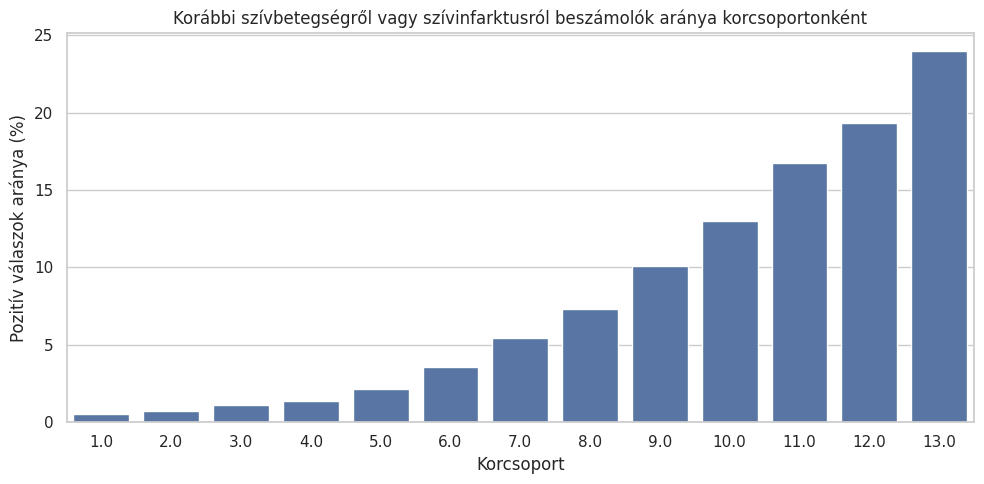

In [19]:
age_analysis = df.groupby("Age")["HeartDiseaseorAttack"].agg(
    ["count", "mean"]
)

age_analysis["Pozitív arány (%)"] = (
    age_analysis["mean"] * 100
)

display(age_analysis)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=age_analysis.index,
    y=age_analysis["Pozitív arány (%)"]
)

plt.title(
    "Korábbi szívbetegségről vagy szívinfarktusról "
    "beszámolók aránya korcsoportonként"
)

plt.xlabel("Korcsoport")
plt.ylabel("Pozitív válaszok aránya (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "korcsoport_pozitiv_arany.png", dpi=200)
plt.show()

11.3. Magas vérnyomás és célváltozó kapcsolata

,count,mean,Pozitív arány (%)
Nincs magas vérnyomás,144851,0.0412,4.1180
Van magas vérnyomás,108829,0.1647,16.4736


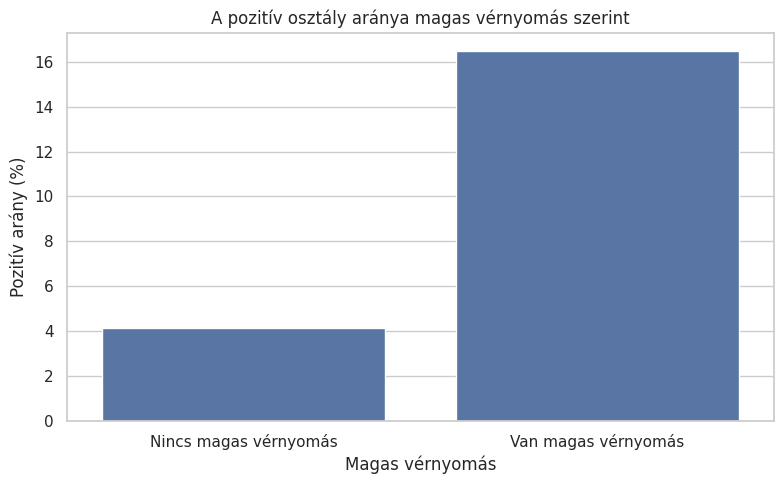

In [20]:
bp_analysis = df.groupby("HighBP")["HeartDiseaseorAttack"].agg(
    ["count", "mean"]
)

bp_analysis["Pozitív arány (%)"] = bp_analysis["mean"] * 100

bp_analysis.index = [
    "Nincs magas vérnyomás",
    "Van magas vérnyomás"
]

display(bp_analysis)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=bp_analysis.index,
    y=bp_analysis["Pozitív arány (%)"]
)

plt.title("A pozitív osztály aránya magas vérnyomás szerint")
plt.xlabel("Magas vérnyomás")
plt.ylabel("Pozitív arány (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "magas_vernyomas.png", dpi=200)
plt.show()

11.4. Cukorbetegség kategóriák összehasonlítása

,count,mean,Pozitív arány (%)
Nincs / terhességi,213703,0.0718,7.1833
Prediabétesz,4631,0.1434,14.3382
Cukorbetegség,35346,0.2229,22.2882


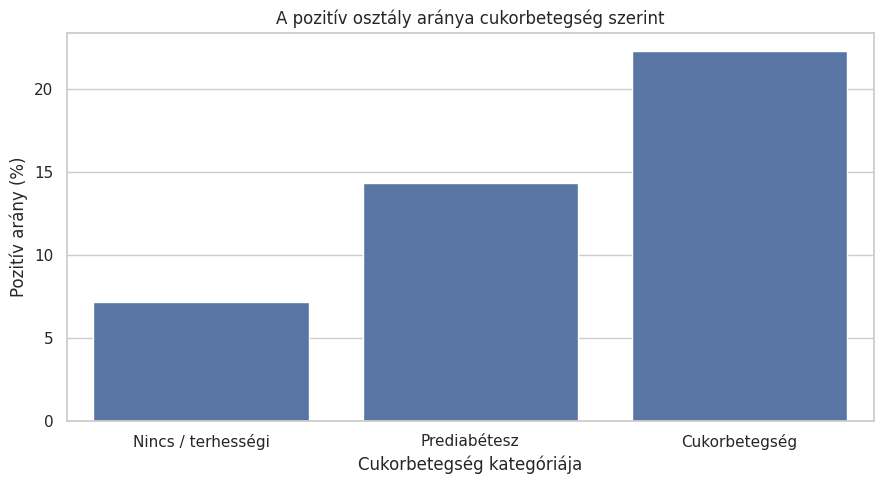

In [21]:
diabetes_labels = {
    0: "Nincs / terhességi",
    1: "Prediabétesz",
    2: "Cukorbetegség"
}

diabetes_analysis = df.groupby("Diabetes")[
    "HeartDiseaseorAttack"
].agg(["count", "mean"])

diabetes_analysis["Pozitív arány (%)"] = (
    diabetes_analysis["mean"] * 100
)

diabetes_analysis.index = [
    diabetes_labels[i] for i in diabetes_analysis.index
]

display(diabetes_analysis)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=diabetes_analysis.index,
    y=diabetes_analysis["Pozitív arány (%)"]
)

plt.title("A pozitív osztály aránya cukorbetegség szerint")
plt.xlabel("Cukorbetegség kategóriája")
plt.ylabel("Pozitív arány (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "diabetes_osszehasonlitas.png", dpi=200)
plt.show()

11.5. Általános egészségi állapot összehasonlítása

,count,mean,Pozitív arány (%)
GenHlth,,,
1.0000,45299,0.0224,2.2429
2.0000,89084,0.0463,4.6338
3.0000,75646,0.1046,10.4619
4.0000,31570,0.2131,21.3114
5.0000,12081,0.3400,33.9955


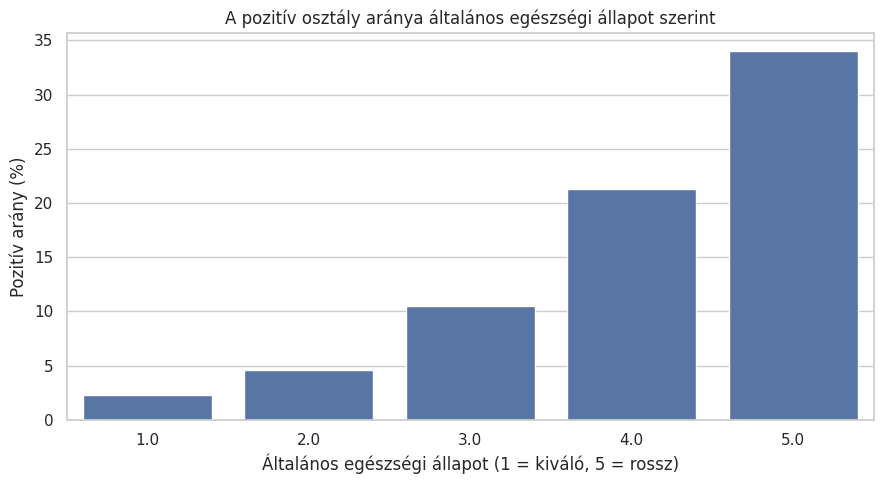

In [22]:
health_analysis = df.groupby("GenHlth")[
    "HeartDiseaseorAttack"
].agg(["count", "mean"])

health_analysis["Pozitív arány (%)"] = (
    health_analysis["mean"] * 100
)

display(health_analysis)

plt.figure(figsize=(9, 5))

sns.barplot(
    x=health_analysis.index,
    y=health_analysis["Pozitív arány (%)"]
)

plt.title("A pozitív osztály aránya általános egészségi állapot szerint")
plt.xlabel("Általános egészségi állapot (1 = kiváló, 5 = rossz)")
plt.ylabel("Pozitív arány (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "egeszsegi_allapot_pozitiv_arany.png", dpi=200)
plt.show()

11.6. Nem és fizikai aktivitás szerinti összehasonlítás

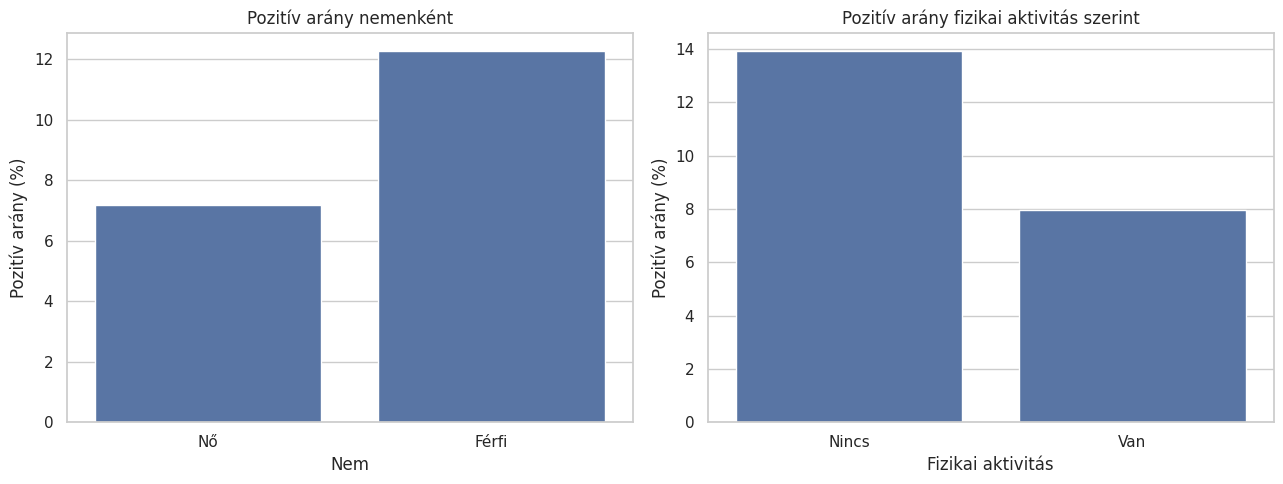

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sex_analysis = df.groupby("Sex")[
    "HeartDiseaseorAttack"
].mean() * 100

sns.barplot(
    x=["Nő", "Férfi"],
    y=sex_analysis.values,
    ax=axes[0]
)

axes[0].set_title("Pozitív arány nemenként")
axes[0].set_xlabel("Nem")
axes[0].set_ylabel("Pozitív arány (%)")

activity_analysis = df.groupby("PhysActivity")[
    "HeartDiseaseorAttack"
].mean() * 100

sns.barplot(
    x=["Nincs", "Van"],
    y=activity_analysis.values,
    ax=axes[1]
)

axes[1].set_title("Pozitív arány fizikai aktivitás szerint")
axes[1].set_xlabel("Fizikai aktivitás")
axes[1].set_ylabel("Pozitív arány (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nem_es_aktivitas.png", dpi=200)
plt.show()

11.7. Stroke és járási nehézség

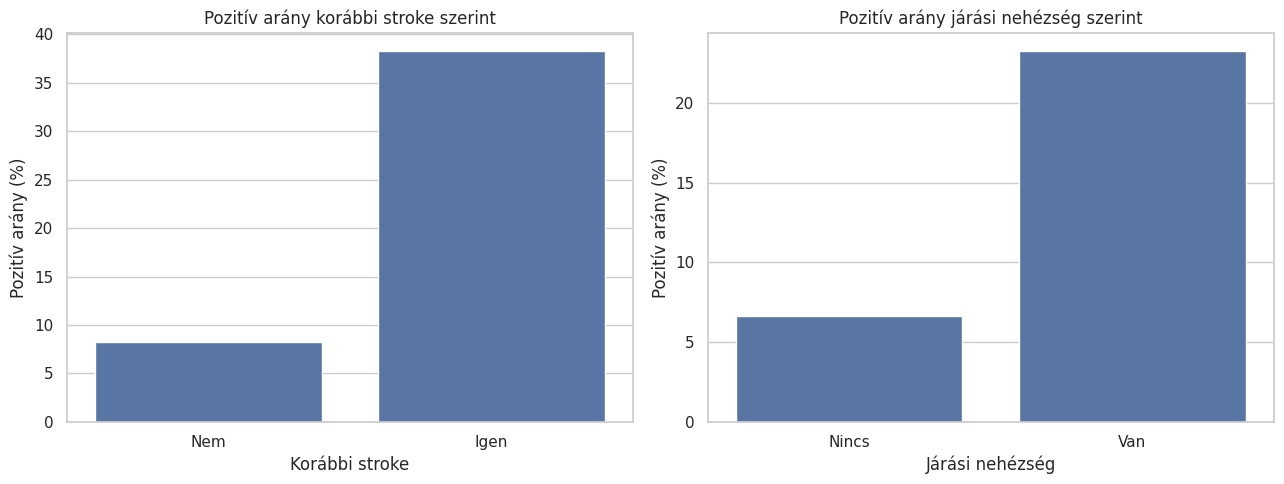

In [24]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

stroke_analysis = df.groupby("Stroke")[
    "HeartDiseaseorAttack"
].mean() * 100

sns.barplot(
    x=["Nem", "Igen"],
    y=stroke_analysis.values,
    ax=axes[0]
)

axes[0].set_title("Pozitív arány korábbi stroke szerint")
axes[0].set_xlabel("Korábbi stroke")
axes[0].set_ylabel("Pozitív arány (%)")

walk_analysis = df.groupby("DiffWalk")[
    "HeartDiseaseorAttack"
].mean() * 100

sns.barplot(
    x=["Nincs", "Van"],
    y=walk_analysis.values,
    ax=axes[1]
)

axes[1].set_title("Pozitív arány járási nehézség szerint")
axes[1].set_xlabel("Járási nehézség")
axes[1].set_ylabel("Pozitív arány (%)")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "stroke_es_jarasi_nehezseg.png", dpi=200)
plt.show()

A grafikonok segítségével láthatóvá válhatnak a csoportok közötti különbségek. Ezek azonban nem bizonyítanak okozati összefüggést. A modellben szereplő változók kapcsolatát később többváltozós megközelítéssel is megvizsgáljuk.

### 12. Potenciálisan esemény utáni változók vizsgálata
Magyarázat

A kutatás egyik fontos módszertani kérdése, hogy egyes változók esetleg már a korábbi szívbetegség vagy szívinfarktus után kialakult állapotot tükrözhetik.

Az alábbi változókat vizsgáljuk:
Változó	Miért érdekes?
DiffWalk	A korábbi egészségi eseményhez kapcsolódó mozgáskorlátozottságot is tükrözheti.
GenHlth	Az általános egészségi állapotot méri.
PhysHlth	A fizikai problémával érintett napok számát méri.
PhysActivity	A fizikai aktivitás változását is tükrözheti.
Stroke	Másik korábbi érrendszeri eseményt jelöl.

Ezekről nem állítható biztosan, hogy a szívbetegség következményeként jelentek meg. A felmérés keresztmetszeti, az időbeli sorrend általában nem állapítható meg.

12.1. A változók kapcsolata a célváltozóval

In [25]:
potential_post_event = [
    "DiffWalk",
    "GenHlth",
    "PhysHlth",
    "PhysActivity",
    "Stroke"
]

post_event_analysis = df[
    potential_post_event + ["HeartDiseaseorAttack"]
].groupby("HeartDiseaseorAttack").mean().T

post_event_analysis.columns = [
    "Nem számolt be",
    "Beszámolt"
]

display(post_event_analysis)

,Nem számolt be,Beszámolt
DiffWalk,0.1426,0.4150
GenHlth,2.4224,3.3676
PhysHlth,3.7313,9.1544
PhysActivity,0.7686,0.6404
Stroke,0.0277,0.1648


12.2. A négy potenciálisan esemény utáni változó vizualizációja

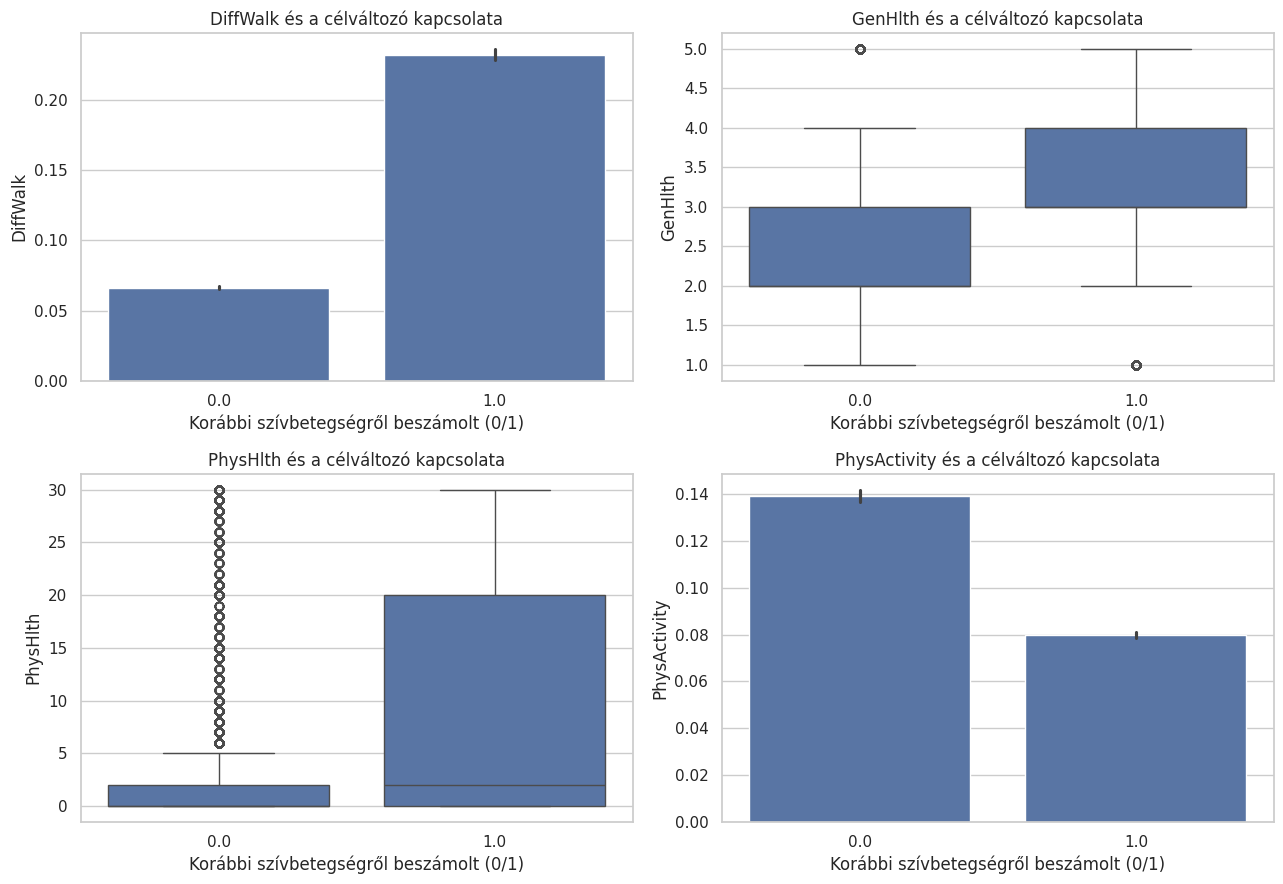

In [26]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, col in zip(
    axes.flatten(),
    ["DiffWalk", "GenHlth", "PhysHlth", "PhysActivity"]
):

    if col in ["GenHlth", "PhysHlth"]:
        sns.boxplot(
            data=df,
            x="HeartDiseaseorAttack",
            y=col,
            ax=ax
        )
    else:
        sns.barplot(
            data=df,
            x=col,
            y="HeartDiseaseorAttack",
            ax=ax
        )

    ax.set_title(f"{col} és a célváltozó kapcsolata")
    ax.set_xlabel("Korábbi szívbetegségről beszámolt (0/1)")
    ax.set_ylabel(col)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "potencialis_esemeny_utani_valtozok.png", dpi=200)
plt.show()

12.3. A két modell változókészletének meghatározása

A teljes modell mind a 21 magyarázó változót használja.

A csökkentett modellből kivesszük a következő négy változót:
- DiffWalk
- GenHlth
- PhysHlth
- PhysActivity
A Stroke változó egyelőre mindkét modellben megmarad.

In [27]:
target_column = "HeartDiseaseorAttack"

X = df.drop(columns=[target_column]).copy()
y = df[target_column].copy()

full_features = X.columns.tolist()

excluded_features = [
    "DiffWalk",
    "GenHlth",
    "PhysHlth",
    "PhysActivity"
]

reduced_features = [
    col for col in full_features
    if col not in excluded_features
]

print("Teljes modell változóinak száma:", len(full_features))
print("Csökkentett modell változóinak száma:", len(reduced_features))

print("\nElhagyott változók:")
print(excluded_features)

print("\nStroke változó mindkét modellben:",
      "Stroke" in full_features and "Stroke" in reduced_features)

Teljes modell változóinak száma: 21
Csökkentett modell változóinak száma: 17

Elhagyott változók:
['DiffWalk', 'GenHlth', 'PhysHlth', 'PhysActivity']

Stroke változó mindkét modellben: True


12.4. Külön Stroke-érzékenységi vizsgálat előkészítése

A Stroke változó elhagyásának hatását is vizsgáljuk. Ez egy külön kiegészítő modell lesz, amelyet azonos tanító-, validációs és tesztadatokon értékelünk.

In [28]:
reduced_without_stroke = [
    col for col in reduced_features
    if col != "Stroke"
]

print("Stroke nélküli változók száma:",
      len(reduced_without_stroke))

Stroke nélküli változók száma: 16


### 13. Adatok előkészítése és rétegzett adatfelosztás
Magyarázat

A gépi tanulás során három különálló adathalmazt használunk.
Adatfelosztás





Tanítóadat

60%


Validációs adat

20%


Tesztadat

20%


- A tanítóadatokon tanítjuk a modelleket.
- A validációs adatokon választjuk ki az optimális döntési küszöböt.
- A tesztadatokon kizárólag a végső teljesítményt értékeljük.
A stratify paraméter megőrzi a célváltozó osztályainak eredeti arányát.

13.1. A felosztás végrehajtása

In [29]:
# Első felosztás: 60% tanító, 40% ideiglenes
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.40,
    random_state=RANDOM_STATE,
    stratify=y
)

# Második felosztás: 20% validáció, 20% teszt
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=RANDOM_STATE,
    stratify=y_temp
)

print("Tanítóadat:", X_train.shape)
print("Validációs adat:", X_val.shape)
print("Tesztadat:", X_test.shape)

Tanítóadat: (152208, 21)
Validációs adat: (50736, 21)
Tesztadat: (50736, 21)


13.2. Osztályarányok ellenőrzése

In [30]:
def split_summary(name, y_part):

    counts = y_part.value_counts().sort_index()

    return {
        "Adathalmaz": name,
        "Összes elemszám": len(y_part),
        "Negatív esetek": counts.get(0, 0),
        "Pozitív esetek": counts.get(1, 0),
        "Pozitív arány (%)": y_part.mean() * 100
    }


split_table = pd.DataFrame([
    split_summary("Tanító", y_train),
    split_summary("Validáció", y_val),
    split_summary("Teszt", y_test),
    split_summary("Teljes adat", y)
])

display(split_table)

,Adathalmaz,Összes elemszám,Negatív esetek,Pozitív esetek,Pozitív arány (%)
0,Tanító,152208,137872,14336,9.4187
1,Validáció,50736,45957,4779,9.4193
2,Teszt,50736,45958,4778,9.4174
3,Teljes adat,253680,229787,23893,9.4186


13.3. Adathalmazok átfedésének ellenőrzése

Az eredeti DataFrame indexeit használjuk annak ellenőrzésére, hogy egyetlen megfigyelés sem került több adathalmazba.

In [31]:
train_indices = set(X_train.index)
val_indices = set(X_val.index)
test_indices = set(X_test.index)

print("Tanító és validáció metszete:",
      len(train_indices & val_indices))

print("Tanító és teszt metszete:",
      len(train_indices & test_indices))

print("Validáció és teszt metszete:",
      len(val_indices & test_indices))

print("Összes rekord megőrizve:",
      len(train_indices | val_indices | test_indices) == len(df))

Tanító és validáció metszete: 0
Tanító és teszt metszete: 0
Validáció és teszt metszete: 0
Összes rekord megőrizve: True


### 14. Adatelőfeldolgozási pipeline létrehozása
Magyarázat

A logisztikus regresszióhoz a különböző típusú változókat megfelelően kell előkészíteni.

Három változócsoportot különböztetünk meg.
Változótípus	Előfeldolgozás
Numerikus	Medián imputálás és standardizálás
Sorrendi/kategorikus	Medián imputálás és OneHotEncoder
Bináris	0/1 értékek változatlanul

A pipeline biztosítja, hogy az előfeldolgozási lépések illesztése kizárólag a tanítóadatokon történjen.

14.1. Előfeldolgozó függvény

In [32]:
def create_preprocessor(feature_list):

    numeric_cols = [
        col for col in numeric_variables
        if col in feature_list
    ]

    categorical_cols = [
        col for col in categorical_variables
        if col in feature_list
    ]

    binary_cols = [
        col for col in binary_variables
        if col in feature_list
    ]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(
            handle_unknown="ignore",
            drop="first"
        ))
    ])

    binary_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols),
        ("binary", binary_pipeline, binary_cols)
    ])

    return preprocessor

Miért használunk drop='first' beállítást?

A OneHotEncoder minden kategorikus változóból több bináris változót hozna létre. A referencia-kategória elhagyásával elkerülhető a tökéletes multikollinearitás, és a regressziós együtthatók könnyebben értelmezhetők.

14.2. Teljes modell pipeline-ja

In [33]:
full_pipeline = Pipeline([
    ("preprocessor", create_preprocessor(full_features)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        C=1.0,
        class_weight=None,
        random_state=RANDOM_STATE
    ))
])

14.3. Csökkentett modell pipeline-ja

In [34]:
reduced_pipeline = Pipeline([
    ("preprocessor", create_preprocessor(reduced_features)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        C=1.0,
        class_weight=None,
        random_state=RANDOM_STATE
    ))
])

14.4. Stroke nélküli modell pipeline-ja

In [35]:
stroke_free_pipeline = Pipeline([
    ("preprocessor", create_preprocessor(reduced_without_stroke)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        C=1.0,
        class_weight=None,
        random_state=RANDOM_STATE
    ))
])

15. Gyakoriságon alapuló alapmodell – DummyClassifier
Magyarázat

A DummyClassifier egy egyszerű összehasonlítási alap.

Nem próbál összefüggéseket felismerni, kizárólag a tanítóadatok osztályarányait használja.

A strategy='prior' beállítás a tanítóadatokban megfigyelt osztályarányoknak megfelelő valószínűségi becslést ad.

Ez azért fontos, mert így össze tudjuk hasonlítani a logisztikus regressziót egy olyan modellel, amely valójában nem tanulja meg a magyarázó változók és a célváltozó kapcsolatát.

15.1. A modell betanítása

In [36]:
dummy_model = DummyClassifier(
    strategy="prior"
)

dummy_model.fit(X_train, y_train)

dummy_probabilities = dummy_model.predict_proba(X_test)[:, 1]

dummy_predictions = dummy_model.predict(X_test)

print("DummyClassifier sikeresen betanítva.")
print("Becsült osztályvalószínűségek:")
print(dummy_model.class_prior_)

DummyClassifier sikeresen betanítva.
Becsült osztályvalószínűségek:
[0.9058131 0.0941869]


15.2. Alapmodell értékelése

In [37]:
dummy_metrics = {
    "Accuracy": accuracy_score(y_test, dummy_predictions),
    "Precision": precision_score(
        y_test, dummy_predictions, zero_division=0
    ),
    "Recall": recall_score(
        y_test, dummy_predictions, zero_division=0
    ),
    "F1-score": f1_score(
        y_test, dummy_predictions, zero_division=0
    ),
    "Average Precision": average_precision_score(
        y_test, dummy_probabilities
    )
}

display(
    pd.DataFrame(
        dummy_metrics,
        index=["DummyClassifier"]
    ).T
)

,DummyClassifier
Accuracy,0.9058
Precision,0.0000
Recall,0.0000
F1-score,0.0000
Average Precision,0.0942


Mivel a prior stratégia a többségi osztályt választja, a modell alapértelmezett előrejelzései várhatóan nem azonosítanak pozitív eseteket. Az Average Precision értéke viszont a pozitív osztály tanítóadatbeli arányával lesz összhangban.

### 16. A logisztikus regressziós modellek betanítása
Magyarázat

Most betanítjuk a két fő modellt.

Mindkét modell pontosan ugyanazt a tanítóadatot használja.
- A teljes modell 21 magyarázó változót használ.
- A csökkentett modell 17 magyarázó változót használ.
A tesztadatokat ebben a szakaszban még nem használjuk fel.

16.1. Teljes modell

In [38]:
full_pipeline.fit(
    X_train[full_features],
    y_train
)

print("A teljes logisztikus regresszió betanult.")

A teljes logisztikus regresszió betanult.


16.2. Csökkentett modell

In [39]:
reduced_pipeline.fit(
    X_train[reduced_features],
    y_train
)

print("A csökkentett logisztikus regresszió betanult.")

A csökkentett logisztikus regresszió betanult.


16.3. Stroke nélküli modell

In [40]:
stroke_free_pipeline.fit(
    X_train[reduced_without_stroke],
    y_train
)

print("A Stroke nélküli érzékenységi modell betanult.")

A Stroke nélküli érzékenységi modell betanult.


16.4. Validációs valószínűségek előállítása

In [41]:
full_val_prob = full_pipeline.predict_proba(
    X_val[full_features]
)[:, 1]

reduced_val_prob = reduced_pipeline.predict_proba(
    X_val[reduced_features]
)[:, 1]

stroke_free_val_prob = stroke_free_pipeline.predict_proba(
    X_val[reduced_without_stroke]
)[:, 1]

print("Validációs valószínűségek elkészültek.")

Validációs valószínűségek elkészültek.


### 17. A teljes modell együtthatóinak értelmezése
Magyarázat

A logisztikus regresszió egyik előnye, hogy az együtthatók alapján megvizsgálható, milyen irányban kapcsolódnak az egyes változók a célváltozóhoz.

Az együtthatók értelmezéséhez esélyhányadost (Odds Ratio) számítunk:   
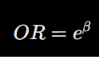

- Ha OR nagyobb, mint 1: magasabb becsült esély.
- Ha OR kisebb, mint 1: alacsonyabb becsült esély.
- Ha OR egyenlő 1-gyel: nincs változás a becsült esélyben.
Ezek nem okozati hatások, és nem azonosak a valószínűségek arányával.

17.1. Együtthatók kinyerése

In [42]:
fitted_preprocessor = (
    full_pipeline.named_steps["preprocessor"]
)

fitted_classifier = (
    full_pipeline.named_steps["classifier"]
)

feature_names = fitted_preprocessor.get_feature_names_out()

coefficients = fitted_classifier.coef_[0]

coefficient_table = pd.DataFrame({
    "Változó": feature_names,
    "Együttható": coefficients
})

coefficient_table["Odds Ratio"] = np.exp(
    coefficient_table["Együttható"]
)

coefficient_table["Előjel"] = np.where(
    coefficient_table["Együttható"] > 0,
    "Pozitív",
    np.where(
        coefficient_table["Együttható"] < 0,
        "Negatív",
        "Nulla"
    )
)

coefficient_table["Értelmezés"] = np.where(
    coefficient_table["Együttható"] > 0,
    "Magasabb becsült esély",
    np.where(
        coefficient_table["Együttható"] < 0,
        "Alacsonyabb becsült esély",
        "Nincs becsült változás"
    )
)

coefficient_table = coefficient_table.sort_values(
    "Együttható",
    ascending=False
)

display(coefficient_table)

,Változó,Együttható,Odds Ratio,Előjel,Értelmezés
8,categorical__GenHlth_5.0,1.8494,6.3558,Pozitív,Magasabb becsült esély
20,categorical__Age_13.0,1.4297,4.1774,Pozitív,Magasabb becsült esély
7,categorical__GenHlth_4.0,1.4251,4.1584,Pozitív,Magasabb becsült esély
19,categorical__Age_12.0,1.1430,3.1363,Pozitív,Magasabb becsült esély
18,categorical__Age_11.0,1.0183,2.7686,Pozitív,Magasabb becsült esély
37,binary__Stroke,0.9899,2.6909,Pozitív,Magasabb becsült esély
6,categorical__GenHlth_3.0,0.9252,2.5224,Pozitív,Magasabb becsült esély
45,binary__Sex,0.7711,2.1621,Pozitív,Magasabb becsült esély
17,categorical__Age_10.0,0.7444,2.1051,Pozitív,Magasabb becsült esély
34,binary__HighChol,0.6389,1.8943,Pozitív,Magasabb becsült esély


17.2. Legfontosabb pozitív és negatív együtthatók

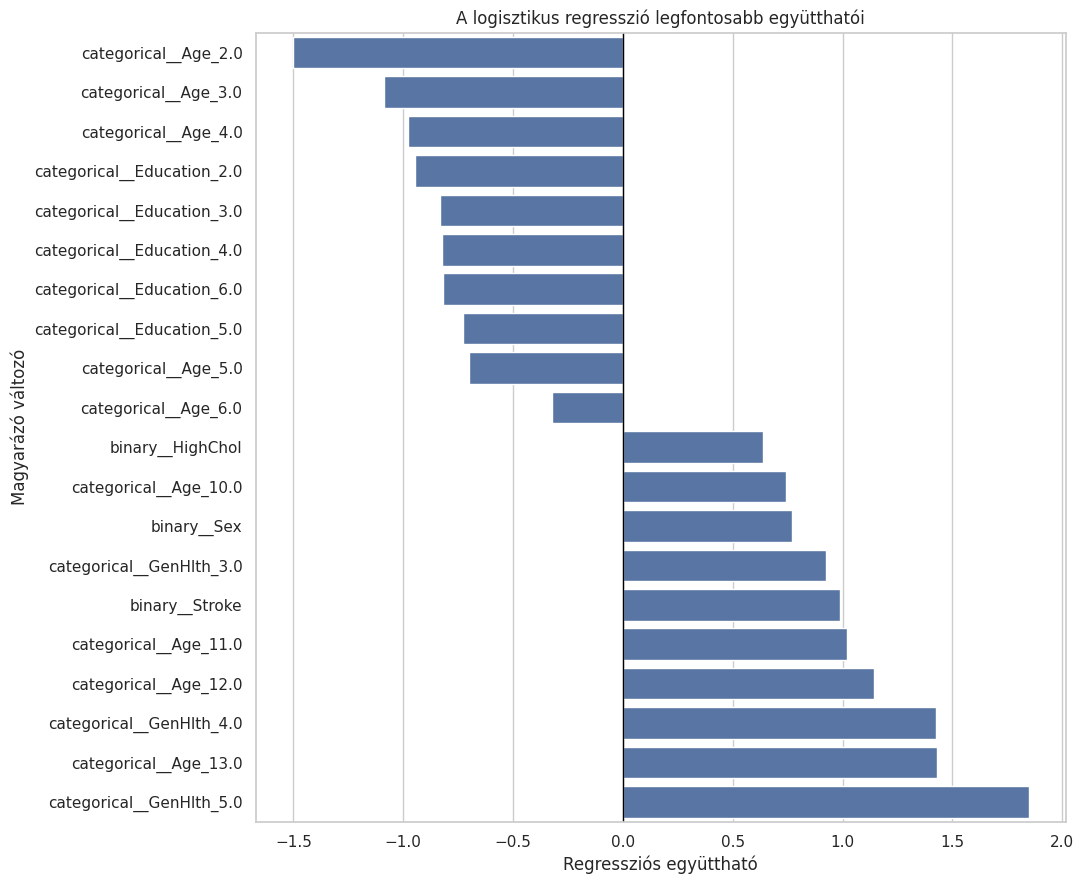

In [43]:
top_positive = coefficient_table.nlargest(
    10, "Együttható"
)

top_negative = coefficient_table.nsmallest(
    10, "Együttható"
)

important_coefficients = pd.concat([
    top_positive,
    top_negative
]).drop_duplicates()

plot_data = important_coefficients.sort_values(
    "Együttható"
)

plt.figure(figsize=(11, 9))

sns.barplot(
    data=plot_data,
    x="Együttható",
    y="Változó"
)

plt.axvline(0, color="black", linewidth=1)

plt.title("A logisztikus regresszió legfontosabb együtthatói")
plt.xlabel("Regressziós együttható")
plt.ylabel("Magyarázó változó")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "modell_egyutthatok.png", dpi=200)
plt.show()

Fontos értelmezési megjegyzés: a OneHotEncoder által létrehozott kategorikus változók együtthatói a kihagyott referencia-kategóriához viszonyítandók. A numerikus változók együtthatói standardizált változókra vonatkoznak, ezért egy szórásnyi változásra értelmezendők.

### 18. Optimális döntési küszöb kiválasztása validációs adatok alapján
Magyarázat

A logisztikus regresszió alapértelmezett döntési küszöbe 0,50.

Osztályegyensúly-hiány esetén azonban ez nem feltétlenül optimális.

Ezért két küszöböt hasonlítunk össze:
1. 0,50-es alapértelmezett küszöb.
2. Validációs adatok alapján kiválasztott F2-optimalizált küszöb.
Az F2-score a Recall értékének nagyobb súlyt ad, így fontosabbá válik a pozitív esetek felismerése.

18.1. F2-optimalizáló függvény

Az összes különböző előrejelzett valószínűségből küszöbjelölteket képezünk. Holtverseny esetén a magasabb küszöböt választjuk.

In [44]:
def find_optimal_threshold(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    # Az utolsó precision és recall értékhez
    # nem tartozik külön threshold.
    precision = precision[:-1]
    recall = recall[:-1]

    f2_values = (
        5 * precision * recall
        / (4 * precision + recall + 1e-12)
    )

    best_f2 = np.max(f2_values)

    # Holtverseny esetén a magasabb küszöböt választjuk.
    best_indices = np.where(
        np.isclose(f2_values, best_f2)
    )[0]

    best_index = best_indices[
        np.argmax(thresholds[best_indices])
    ]

    return {
        "threshold": thresholds[best_index],
        "precision": precision[best_index],
        "recall": recall[best_index],
        "f2": f2_values[best_index]
    }

18.2. Küszöbök kiválasztása

In [45]:
full_optimal = find_optimal_threshold(
    y_val,
    full_val_prob
)

reduced_optimal = find_optimal_threshold(
    y_val,
    reduced_val_prob
)

stroke_free_optimal = find_optimal_threshold(
    y_val,
    stroke_free_val_prob
)

print("Teljes modell optimális küszöbe:",
      full_optimal["threshold"])

print("Csökkentett modell optimális küszöbe:",
      reduced_optimal["threshold"])

print("Stroke nélküli modell optimális küszöbe:",
      stroke_free_optimal["threshold"])

Teljes modell optimális küszöbe: 0.08550761925261599
Csökkentett modell optimális küszöbe: 0.09538362216463647
Stroke nélküli modell optimális küszöbe: 0.10051943077621131


18.3. Validációs eredmények összehasonlítása

In [46]:
def threshold_metrics(y_true, probabilities, threshold):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    return {
        "Küszöb": threshold,
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "F2-score": fbeta_score(
            y_true, predictions, beta=2, zero_division=0
        )
    }


validation_results = []

for name, probabilities, optimal in [
    ("Teljes modell", full_val_prob, full_optimal),
    ("Csökkentett modell", reduced_val_prob, reduced_optimal)
]:

    for threshold_name, threshold in [
        ("Alapértelmezett", 0.50),
        ("F2-optimalizált", optimal["threshold"])
    ]:

        result = threshold_metrics(
            y_val,
            probabilities,
            threshold
        )

        result["Modell"] = name
        result["Küszöb típusa"] = threshold_name

        validation_results.append(result)


validation_table = pd.DataFrame(validation_results)

display(
    validation_table[
        [
            "Modell",
            "Küszöb típusa",
            "Küszöb",
            "Precision",
            "Recall",
            "F1-score",
            "F2-score"
        ]
    ]
)

,Modell,Küszöb típusa,Küszöb,Precision,Recall,F1-score,F2-score
0,Teljes modell,Alapértelmezett,0.5000,0.5297,0.1268,0.2046,0.1496
1,Teljes modell,F2-optimalizált,0.0855,0.2355,0.8165,0.3656,0.5468
2,Csökkentett modell,Alapértelmezett,0.5000,0.5316,0.0898,0.1536,0.1077
3,Csökkentett modell,F2-optimalizált,0.0954,0.2264,0.7788,0.3508,0.5234


In [47]:
FULL_THRESHOLD = full_optimal["threshold"]
REDUCED_THRESHOLD = reduced_optimal["threshold"]

print("Rögzített teljes modell küszöbe:", FULL_THRESHOLD)
print("Rögzített csökkentett modell küszöbe:", REDUCED_THRESHOLD)

Rögzített teljes modell küszöbe: 0.08550761925261599
Rögzített csökkentett modell küszöbe: 0.09538362216463647


Fontos: innentől a teszthalmaz eredményeit nem használjuk fel a küszöbök módosítására.

### 19. Végső modellértékelés a teszthalmazon
Magyarázat

Ebben a szakaszban végre megvizsgáljuk a modellek teljesítményét a korábban elkülönített tesztadatokon.

Három megközelítést hasonlítunk össze:
1. DummyClassifier.
2. Teljes logisztikus regresszió.
3. Csökkentett logisztikus regresszió.
A logisztikus regressziós modelleket két küszöbértékkel is megvizsgáljuk.

19.1. Tesztadatokon történő valószínűségbecslés

In [48]:
# Tesztadatok valószínűségi becslései
full_test_prob = full_pipeline.predict_proba(
    X_test[full_features]
)[:, 1]

reduced_test_prob = reduced_pipeline.predict_proba(
    X_test[reduced_features]
)[:, 1]

# Dummy valószínűségek
dummy_test_prob = dummy_model.predict_proba(
    X_test
)[:, 1]

# Előrejelzések két küszöbértékkel
full_pred_050 = (
    full_test_prob >= 0.50
).astype(int)

full_pred_opt = (
    full_test_prob >= FULL_THRESHOLD
).astype(int)

reduced_pred_050 = (
    reduced_test_prob >= 0.50
).astype(int)

reduced_pred_opt = (
    reduced_test_prob >= REDUCED_THRESHOLD
).astype(int)

print("A tesztadatokon történő előrejelzések elkészültek.")

A tesztadatokon történő előrejelzések elkészültek.


### 20. Precision-Recall görbe és Average Precision
Magyarázat

Osztályegyensúly-hiány esetén a Precision-Recall görbe különösen fontos.

A grafikon két mérőszám kapcsolatát mutatja:
- Precision: a pozitívnak előre jelzett esetek közül mennyi volt valóban pozitív.
- Recall: a tényleges pozitív esetek közül mennyit ismert fel a modell.
Két különböző területmutatót számítunk:
1. Average Precision (AP).
2. Trapézszabály szerinti PR-AUC.
A kettő nem teljesen azonos, ezért külön kezeljük őket.

20.1. Mérőszámok kiszámítása

In [49]:
def calculate_pr_metrics(y_true, probabilities):

    precision, recall, thresholds = precision_recall_curve(
        y_true,
        probabilities
    )

    ap = average_precision_score(
        y_true,
        probabilities
    )

    pr_auc = auc(
        recall,
        precision
    )

    return {
        "Precision": precision,
        "Recall": recall,
        "Average Precision": ap,
        "Trapézszabály szerinti PR-AUC": pr_auc
    }


full_pr = calculate_pr_metrics(
    y_test,
    full_test_prob
)

reduced_pr = calculate_pr_metrics(
    y_test,
    reduced_test_prob
)

dummy_pr = calculate_pr_metrics(
    y_test,
    dummy_test_prob
)

20.2. Összehasonlító táblázat

In [50]:
pr_comparison = pd.DataFrame([
    {
        "Modell": "DummyClassifier",
        "Pozitív osztály aránya": y_test.mean(),
        "Average Precision": dummy_pr["Average Precision"],
        "Trapézszabály szerinti PR-AUC":
            dummy_pr["Trapézszabály szerinti PR-AUC"]
    },
    {
        "Modell": "Teljes modell",
        "Pozitív osztály aránya": y_test.mean(),
        "Average Precision": full_pr["Average Precision"],
        "Trapézszabály szerinti PR-AUC":
            full_pr["Trapézszabály szerinti PR-AUC"]
    },
    {
        "Modell": "Csökkentett modell",
        "Pozitív osztály aránya": y_test.mean(),
        "Average Precision": reduced_pr["Average Precision"],
        "Trapézszabály szerinti PR-AUC":
            reduced_pr["Trapézszabály szerinti PR-AUC"]
    }
])

display(pr_comparison)

pr_comparison.to_csv(
    OUTPUT_DIR / "pr_osszehasonlitas.csv",
    index=False
)

,Modell,Pozitív osztály aránya,Average Precision,Trapézszabály szerinti PR-AUC
0,DummyClassifier,0.0942,0.0942,0.5471
1,Teljes modell,0.0942,0.3708,0.3706
2,Csökkentett modell,0.0942,0.3334,0.3332


20.3. Közös Precision-Recall grafikon

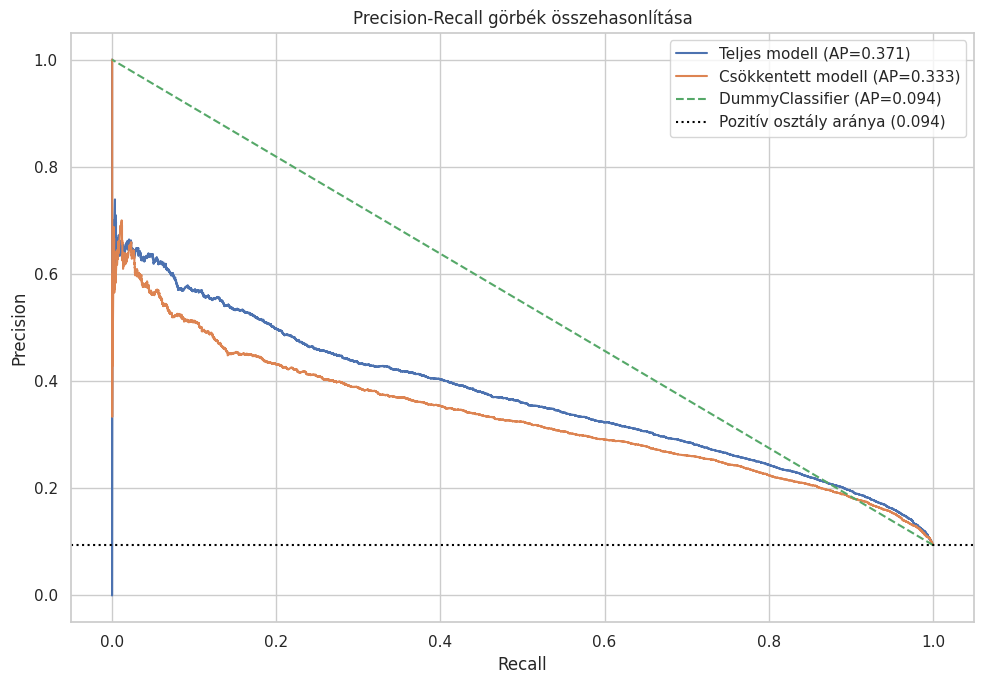

In [51]:
plt.figure(figsize=(10, 7))

plt.plot(
    full_pr["Recall"],
    full_pr["Precision"],
    label=f"Teljes modell (AP={full_pr['Average Precision']:.3f})"
)

plt.plot(
    reduced_pr["Recall"],
    reduced_pr["Precision"],
    label=f"Csökkentett modell (AP={reduced_pr['Average Precision']:.3f})"
)

plt.plot(
    dummy_pr["Recall"],
    dummy_pr["Precision"],
    label=f"DummyClassifier (AP={dummy_pr['Average Precision']:.3f})",
    linestyle="--"
)

# Pozitív osztály aránya
plt.axhline(
    y=y_test.mean(),
    linestyle=":",
    color="black",
    label=f"Pozitív osztály aránya ({y_test.mean():.3f})"
)

plt.title("Precision-Recall görbék összehasonlítása")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "precision_recall_gorbe.png", dpi=200)
plt.show()

Értelmezés

A pozitív osztály aránya a referenciaérték. Ha a modell Average Precision értéke ezt meghaladja, akkor a pozitív esetek rangsorolásában jobb teljesítményt nyújt, mint a gyakoriságon alapuló véletlenszerű rangsorolásnak megfelelő alapmodell.

Minél nagyobb a referenciaértékhez viszonyított javulás, annál hasznosabb információt nyújt a modell rangsorolása.


---



### 21. További modellértékelési mutatók

21.1. Általános értékelő függvény

In [52]:
def evaluate_model(y_true, probabilities, threshold):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0

    return {
        "Küszöb": threshold,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "F2-score": fbeta_score(
            y_true, predictions, beta=2, zero_division=0
        ),
        "Specificity": specificity,
        "Balanced accuracy": balanced_accuracy_score(
            y_true, predictions
        ),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp
    }

21.2. A négy modellbeállítás értékelése

In [53]:
test_results = []

models_to_evaluate = [
    ("Teljes modell", full_test_prob, 0.50),
    ("Teljes modell", full_test_prob, FULL_THRESHOLD),
    ("Csökkentett modell", reduced_test_prob, 0.50),
    ("Csökkentett modell", reduced_test_prob, REDUCED_THRESHOLD)
]

for model_name, probabilities, threshold in models_to_evaluate:

    result = evaluate_model(
        y_test,
        probabilities,
        threshold
    )

    result["Modell"] = model_name

    test_results.append(result)

test_results_df = pd.DataFrame(test_results)

display(test_results_df)

,Küszöb,Accuracy,Precision,Recall,F1-score,F2-score,Specificity,Balanced accuracy,TN,FP,FN,TP,Modell
0,0.5000,0.9083,0.5567,0.1296,0.2102,0.1530,0.9893,0.5594,45465,493,4159,619,Teljes modell
1,0.0855,0.7282,0.2332,0.8242,0.3635,0.5469,0.7182,0.7712,33006,12952,840,3938,Teljes modell
2,0.5000,0.9064,0.5175,0.0864,0.1481,0.1037,0.9916,0.5390,45573,385,4365,413,Csökkentett modell
3,0.0954,0.7268,0.2275,0.7932,0.3536,0.5297,0.7199,0.7566,33087,12871,988,3790,Csökkentett modell


21.3. Eredménytáblázat mentése

In [54]:
test_results_df.to_csv(
    OUTPUT_DIR / "teszt_modell_ertekeles.csv",
    index=False
)

print("A modellértékelési táblázat mentve.")

A modellértékelési táblázat mentve.




---



## 22. Confusion matrix – konfúziós mátrix
Magyarázat

A konfúziós mátrix segítségével megvizsgáljuk, hogy a modell milyen típusú hibákat követ el.

Négy esetet különböztetünk meg:
- True Positive (TP): helyesen felismert pozitív eset.
- True Negative (TN): helyesen felismert negatív eset.
- False Positive (FP): tévesen pozitívnak minősített eset.
- False Negative (FN): kihagyott pozitív eset.
A kutatásban különösen fontos a False Negative, mivel ezek azok a válaszadók, akik korábbi szívbetegségről vagy szívinfarktusról számoltak be, de a modell nem ismerte fel őket.

22.1. Confusion matrix megjelenítő függvény

In [55]:
def plot_confusion(y_true, probabilities, threshold, title, filename):

    predictions = (
        probabilities >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    plt.figure(figsize=(7, 5))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Negatív", "Pozitív"],
        yticklabels=["Negatív", "Pozitív"]
    )

    plt.title(
        f"{title}\nKüszöb: {threshold:.4f}\n"
        f"TN={tn}, FP={fp}, FN={fn}, TP={tp}"
    )

    plt.xlabel("Előre jelzett osztály")
    plt.ylabel("Tényleges osztály")

    plt.tight_layout()

    plt.savefig(
        OUTPUT_DIR / filename,
        dpi=200
    )

    plt.show()

22.2. A négy konfúziós mátrix

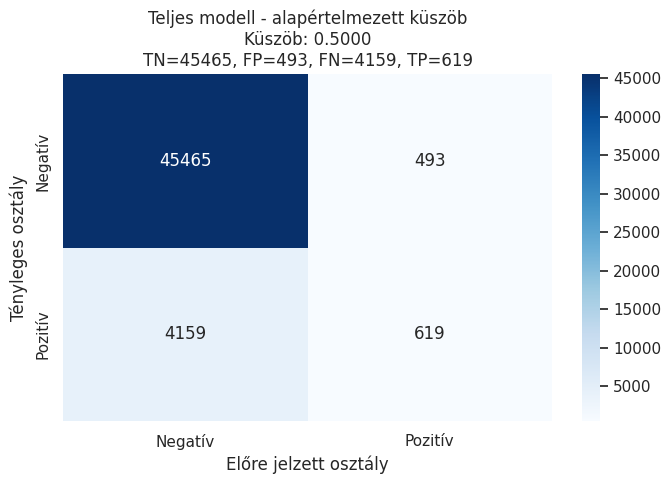

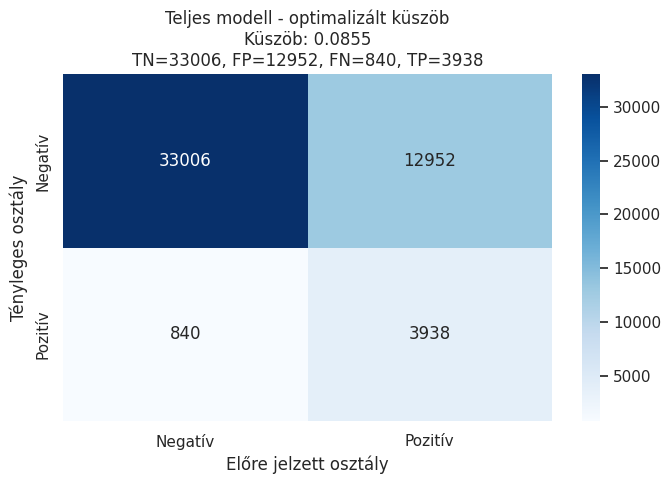

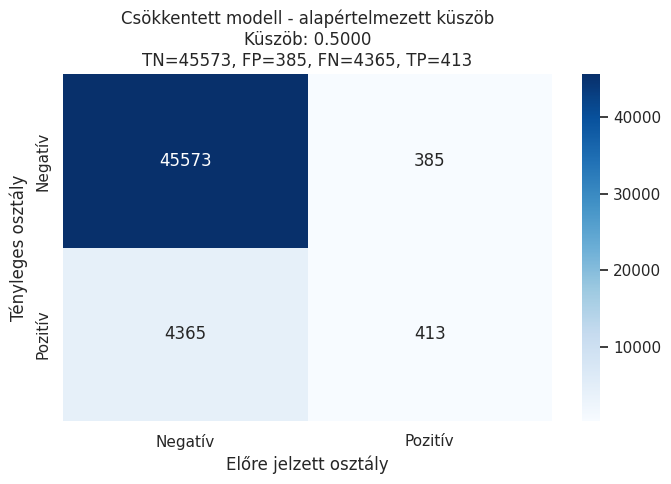

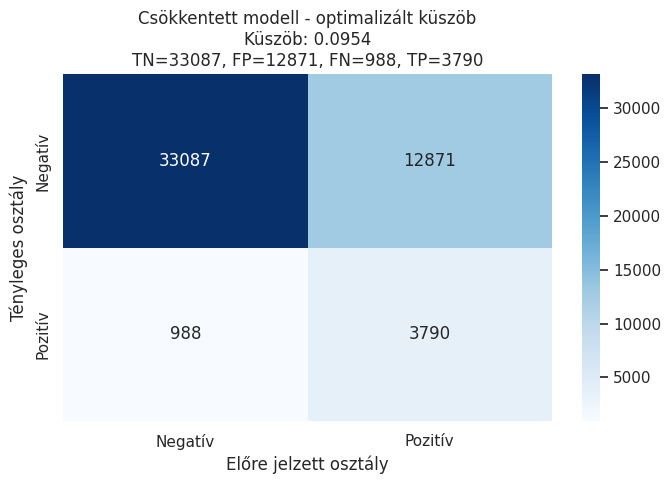

In [56]:
plot_confusion(
    y_test,
    full_test_prob,
    0.50,
    "Teljes modell - alapértelmezett küszöb",
    "confusion_teljes_050.png"
)

plot_confusion(
    y_test,
    full_test_prob,
    FULL_THRESHOLD,
    "Teljes modell - optimalizált küszöb",
    "confusion_teljes_optimalis.png"
)

plot_confusion(
    y_test,
    reduced_test_prob,
    0.50,
    "Csökkentett modell - alapértelmezett küszöb",
    "confusion_csokkentett_050.png"
)

plot_confusion(
    y_test,
    reduced_test_prob,
    REDUCED_THRESHOLD,
    "Csökkentett modell - optimalizált küszöb",
    "confusion_csokkentett_optimalis.png"
)

Értelmezés

A két küszöbérték összehasonlításakor várhatóan a küszöb csökkentése növeli a pozitívnak minősített megfigyelések számát.

Ez jellemzően:
- növeli a Recall értékét;
- csökkenti a False Negative esetek számát;
- növeli a False Positive esetek számát.
A konkrét változásokat azonban kizárólag a kiszámított eredmények alapján értelmezzük.

---



23. Téves pozitív és negatív esetek 1000 válaszadóra vetítve
Magyarázat

A nyers hibaszámok mellett fontos, hogy az eredményeket egységes nevezővel is összehasonlítsuk.

A számítás alapja minden esetben a teljes teszthalmaz elemszáma.

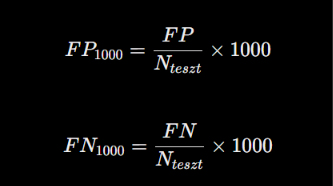

23.1. Hibák kiszámítása

In [57]:
error_results = []

for model_name, probabilities, threshold in models_to_evaluate:

    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    ).ravel()

    n_test = len(y_test)

    error_results.append({
        "Modell": model_name,
        "Küszöb": threshold,
        "FP": fp,
        "FN": fn,
        "FP / 1000 válaszadó": fp / n_test * 1000,
        "FN / 1000 válaszadó": fn / n_test * 1000
    })

error_table = pd.DataFrame(error_results)

display(error_table)

,Modell,Küszöb,FP,FN,FP / 1000 válaszadó,FN / 1000 válaszadó
0,Teljes modell,0.5000,493,4159,9.7170,81.9734
1,Teljes modell,0.0855,12952,840,255.2822,16.5563
2,Csökkentett modell,0.5000,385,4365,7.5883,86.0336
3,Csökkentett modell,0.0954,12871,988,253.6857,19.4734


23.2. FP/FN összehasonlító grafikon

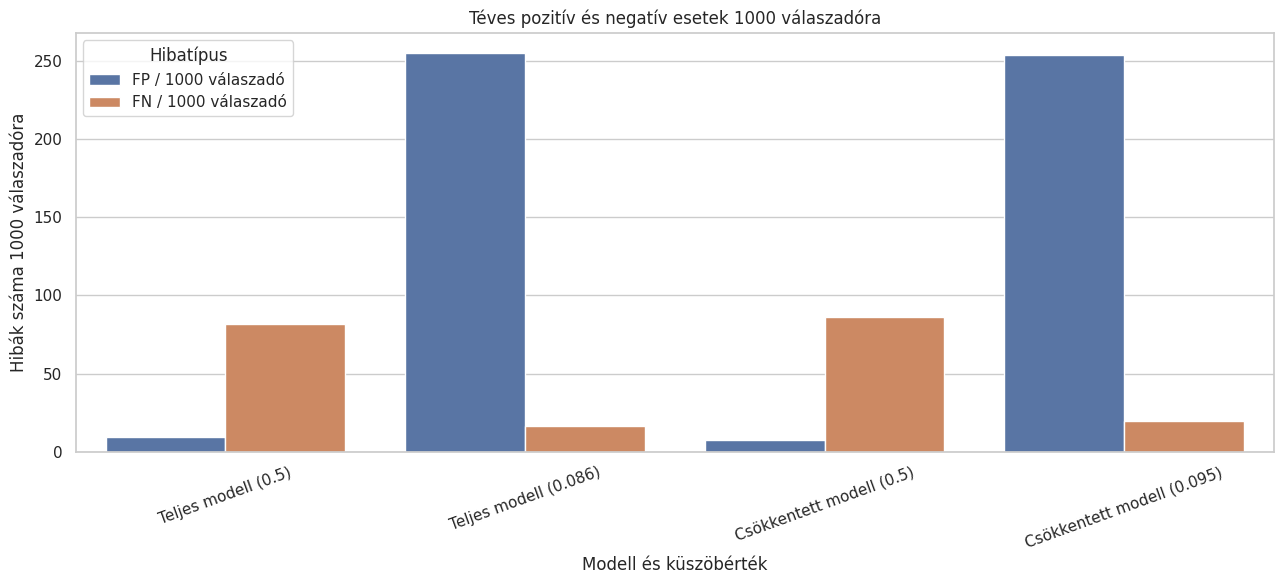

In [58]:
plot_errors = error_table.melt(
    id_vars=["Modell", "Küszöb"],
    value_vars=[
        "FP / 1000 válaszadó",
        "FN / 1000 válaszadó"
    ],
    var_name="Hibatípus",
    value_name="Hibák száma"
)

plot_errors["Modell és küszöb"] = (
    plot_errors["Modell"]
    + " ("
    + plot_errors["Küszöb"].round(3).astype(str)
    + ")"
)

plt.figure(figsize=(13, 6))

sns.barplot(
    data=plot_errors,
    x="Modell és küszöb",
    y="Hibák száma",
    hue="Hibatípus"
)

plt.title("Téves pozitív és negatív esetek 1000 válaszadóra")
plt.xlabel("Modell és küszöbérték")
plt.ylabel("Hibák száma 1000 válaszadóra")

plt.xticks(rotation=20)
plt.tight_layout()

plt.savefig(OUTPUT_DIR / "fp_fn_1000.png", dpi=200)
plt.show()

23.3. Eredménytáblázat mentése

In [59]:
error_table.to_csv(
    OUTPUT_DIR / "fp_fn_1000.csv",
    index=False
)



---



### 24. Alcsoport-összehasonlítás – nők és férfiak
Magyarázat

Ebben a szakaszban megvizsgáljuk, hogy a teljes logisztikus regressziós modell hogyan teljesít a női és férfi válaszadók esetében.

A feladat szerint a teljes modell validációs adatok alapján kiválasztott F2-optimalizált küszöbét használjuk.

A Kaggle-adatkészlet kódolása:
- 0 = nő.
- 1 = férfi.
Az összehasonlítás kizárólag a tesztadatokon történik.

24.1. Alcsoportok létrehozása

In [60]:
subgroup_predictions = (
    full_test_prob >= FULL_THRESHOLD
).astype(int)

subgroup_data = pd.DataFrame({
    "Sex": X_test["Sex"].values,
    "Actual": y_test.values,
    "Predicted": subgroup_predictions
}, index=y_test.index)

subgroup_results = []

for sex_value, sex_name in [
    (0, "Nő"),
    (1, "Férfi")
]:

    group = subgroup_data[
        subgroup_data["Sex"] == sex_value
    ]

    tn, fp, fn, tp = confusion_matrix(
        group["Actual"],
        group["Predicted"],
        labels=[0, 1]
    ).ravel()

    subgroup_results.append({
        "Csoport": sex_name,
        "Összes elemszám": len(group),
        "Negatív esetek": tn + fp,
        "Pozitív esetek": tp + fn,
        "Pozitív arány (%)":
            group["Actual"].mean() * 100,
        "Precision": precision_score(
            group["Actual"],
            group["Predicted"],
            zero_division=0
        ),
        "Recall": recall_score(
            group["Actual"],
            group["Predicted"],
            zero_division=0
        ),
        "FP": fp,
        "FN": fn
    })

subgroup_table = pd.DataFrame(subgroup_results)

display(subgroup_table)

,Csoport,Összes elemszám,Negatív esetek,Pozitív esetek,Pozitív arány (%),Precision,Recall,FP,FN
0,Nő,28048,26035,2013,7.1770,0.2093,0.7596,5778,484
1,Férfi,22688,19923,2765,12.1871,0.2514,0.8712,7174,356


24.2. Alcsoportok vizualizációja

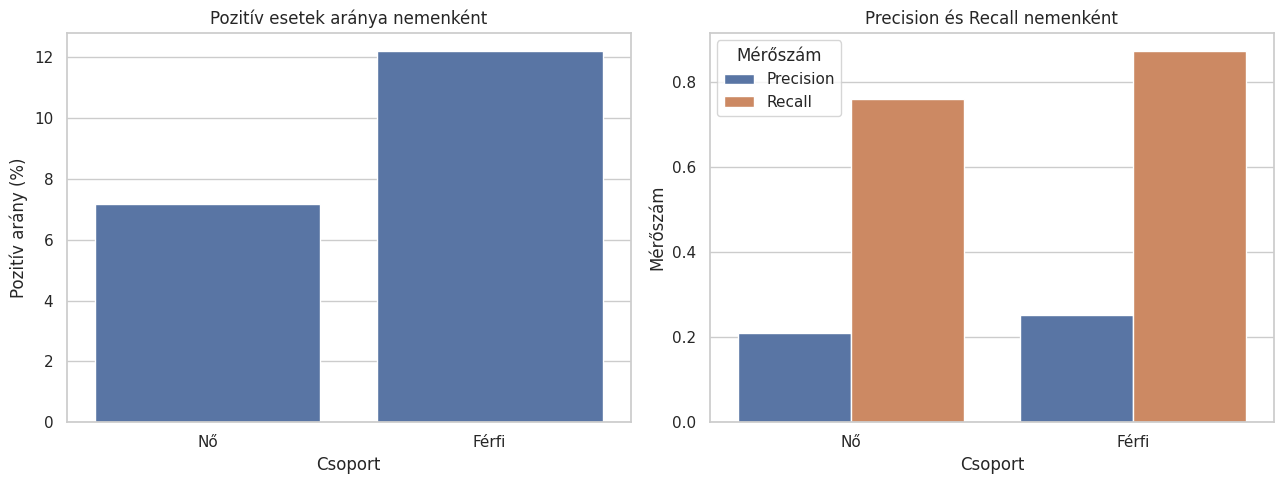

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.barplot(
    data=subgroup_table,
    x="Csoport",
    y="Pozitív arány (%)",
    ax=axes[0]
)

axes[0].set_title("Pozitív esetek aránya nemenként")
axes[0].set_xlabel("Csoport")
axes[0].set_ylabel("Pozitív arány (%)")

subgroup_long = subgroup_table.melt(
    id_vars="Csoport",
    value_vars=["Precision", "Recall"],
    var_name="Mérőszám",
    value_name="Érték"
)

sns.barplot(
    data=subgroup_long,
    x="Csoport",
    y="Érték",
    hue="Mérőszám",
    ax=axes[1]
)

axes[1].set_title("Precision és Recall nemenként")
axes[1].set_xlabel("Csoport")
axes[1].set_ylabel("Mérőszám")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "alcsoport_osszehasonlitas.png", dpi=200)
plt.show()

24.3. Alcsoportok validációja

In [62]:
assert subgroup_table["Összes elemszám"].sum() == len(y_test)

assert subgroup_table["Pozitív esetek"].sum() == int(
    y_test.sum()
)

assert subgroup_table["Negatív esetek"].sum() == int(
    (y_test == 0).sum()
)

print("Az alcsoportok elemszámai megfelelőek.")

Az alcsoportok elemszámai megfelelőek.


Az alcsoportok közötti eltérések értelmezésénél figyelembe kell venni az elemszámokat és a pozitív esetek arányát. A különbségek önmagukban nem bizonyítanak méltánytalanságot vagy statisztikailag szignifikáns eltérést.

---



### 25. További érzékenységi vizsgálat – Stroke változó elhagyása
Magyarázat

A Stroke változó egy másik korábbi érrendszeri eseményt jelöl.

Nem tudjuk biztosan, hogy időben a szívbetegség előtt vagy után következett-e be.

Ezért külön megvizsgáljuk, hogy a változó elhagyása milyen hatással van a modell teljesítményére.

A Stroke nélküli modellt már korábban betanítottuk. Most kiválasztjuk hozzá a validációs F2-optimalizált küszöböt, majd a teszthalmazon értékeljük.

25.1. Optimális küszöb

In [63]:
stroke_free_optimal = find_optimal_threshold(
    y_val,
    stroke_free_val_prob
)

STROKE_FREE_THRESHOLD = stroke_free_optimal["threshold"]

print(
    "Stroke nélküli modell optimális küszöbe:",
    STROKE_FREE_THRESHOLD
)

Stroke nélküli modell optimális küszöbe: 0.10051943077621131


25.2. Tesztadatok értékelése

In [64]:
stroke_free_test_prob = stroke_free_pipeline.predict_proba(
    X_test[reduced_without_stroke]
)[:, 1]

stroke_free_result = evaluate_model(
    y_test,
    stroke_free_test_prob,
    STROKE_FREE_THRESHOLD
)

display(
    pd.DataFrame(
        stroke_free_result,
        index=["Stroke nélküli modell"]
    ).T
)

,Stroke nélküli modell
Küszöb,0.1005
Accuracy,0.7251
Precision,0.2244
Recall,0.7813
F1-score,0.3487
F2-score,0.5221
Specificity,0.7192
Balanced accuracy,0.7503
TN,33055.0000
FP,12903.0000


25.3. Összehasonlítás a csökkentett modellel

In [65]:
stroke_sensitivity_table = pd.DataFrame([
    {
        "Modell": "Csökkentett, Stroke változóval",
        **evaluate_model(
            y_test,
            reduced_test_prob,
            REDUCED_THRESHOLD
        ),
        "Average Precision": average_precision_score(
            y_test,
            reduced_test_prob
        )
    },
    {
        "Modell": "Csökkentett, Stroke nélkül",
        **stroke_free_result,
        "Average Precision": average_precision_score(
            y_test,
            stroke_free_test_prob
        )
    }
])

display(stroke_sensitivity_table)

,Modell,Küszöb,Accuracy,Precision,Recall,F1-score,F2-score,Specificity,Balanced accuracy,TN,FP,FN,TP,Average Precision
0,"Csökkentett, Stroke változóval",0.0954,0.7268,0.2275,0.7932,0.3536,0.5297,0.7199,0.7566,33087,12871,988,3790,0.3334
1,"Csökkentett, Stroke nélkül",0.1005,0.7251,0.2244,0.7813,0.3487,0.5221,0.7192,0.7503,33055,12903,1045,3733,0.3056


Ez a vizsgálat megmutatja, hogy a Stroke változó elhagyása mennyiben módosítja a teljesítményt. Az eredmény nem bizonyítja, hogy a Stroke okozza a célváltozó felismerhetőségét.

---



### 26. Osztálykiegyensúlyozás vizsgálata – class_weight='balanced'
Magyarázat

Az elsődleges modelleknél nem alkalmaztunk automatikus osztálykiegyensúlyozást.

Most kiegészítő vizsgálatként megnézzük, hogyan változik a logisztikus regresszió teljesítménye, ha a kisebbségi osztály nagyobb súlyt kap a tanítás során.

A class_weight='balanced' automatikusan meghatározza az osztálysúlyokat a tanítóadatok gyakorisága alapján.

Fontos, hogy a validációs és tesztadatok osztályeloszlását továbbra sem módosítjuk.

26.1. Súlyozott modell betanítása

In [66]:
balanced_pipeline = Pipeline([
    ("preprocessor", create_preprocessor(full_features)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ))
])

balanced_pipeline.fit(
    X_train[full_features],
    y_train
)

print("A kiegyensúlyozott modell betanult.")

A kiegyensúlyozott modell betanult.


26.2. Validációs küszöb optimalizálása

In [67]:
balanced_val_prob = balanced_pipeline.predict_proba(
    X_val[full_features]
)[:, 1]

balanced_optimal = find_optimal_threshold(
    y_val,
    balanced_val_prob
)

BALANCED_THRESHOLD = balanced_optimal["threshold"]

print(
    "Balanced modell optimális küszöbe:",
    BALANCED_THRESHOLD
)

Balanced modell optimális küszöbe: 0.4845180075125909


26.3. Tesztadatok értékelése

In [68]:
balanced_test_prob = balanced_pipeline.predict_proba(
    X_test[full_features]
)[:, 1]

balanced_result = evaluate_model(
    y_test,
    balanced_test_prob,
    BALANCED_THRESHOLD
)

balanced_result["Modell"] = "Class weight balanced"

balanced_result["Average Precision"] = (
    average_precision_score(
        y_test,
        balanced_test_prob
    )
)

display(
    pd.DataFrame(
        balanced_result,
        index=["Balanced modell"]
    ).T
)

,Balanced modell
Küszöb,0.4845
Accuracy,0.7384
Precision,0.2388
Recall,0.8131
F1-score,0.3692
F2-score,0.5491
Specificity,0.7306
Balanced accuracy,0.7718
TN,33576
FP,12382


26.4. Az elsődleges és kiegyensúlyozott modell összehasonlítása

In [69]:
balanced_comparison = pd.DataFrame([
    {
        "Modell": "Teljes modell - eredeti",
        **evaluate_model(
            y_test,
            full_test_prob,
            FULL_THRESHOLD
        ),
        "Average Precision": average_precision_score(
            y_test,
            full_test_prob
        )
    },
    {
        "Modell": "Teljes modell - balanced",
        **balanced_result
    }
])

display(balanced_comparison)

balanced_comparison.to_csv(
    OUTPUT_DIR / "balanced_osszehasonlitas.csv",
    index=False
)

,Modell,Küszöb,Accuracy,Precision,Recall,F1-score,F2-score,Specificity,Balanced accuracy,TN,FP,FN,TP,Average Precision
0,Teljes modell - eredeti,0.0855,0.7282,0.2332,0.8242,0.3635,0.5469,0.7182,0.7712,33006,12952,840,3938,0.3708
1,Class weight balanced,0.4845,0.7384,0.2388,0.8131,0.3692,0.5491,0.7306,0.7718,33576,12382,893,3885,0.3707


Értelmezés

A két modell eredményéből megvizsgáljuk, hogy a kiegyensúlyozás mennyivel növeli vagy csökkenti a Recall értékét, és ennek milyen ára van a Precision, az FP és az FN tekintetében.

A kiegyensúlyozott modell eredményeit külön kezeljük, nem keverjük össze a két elsődleges modell eredményeivel.

---



### 27. A teljes és csökkentett modell összehasonlítása
Magyarázat

Ebben a szakaszban összegyűjtjük a kutatás legfontosabb eredményeit.

Különösen fontos kérdés, hogy a potenciálisan esemény utáni változók elhagyásakor mennyivel romlik vagy javul a modell felismerési teljesítménye.

A következő táblázatban a teszthalmazon számított eredményeket hasonlítjuk össze.

27.1. Összefoglaló táblázat

In [70]:
summary_rows = []

for name, probabilities, threshold in [
    ("Teljes modell", full_test_prob, FULL_THRESHOLD),
    ("Csökkentett modell", reduced_test_prob, REDUCED_THRESHOLD),
    ("Stroke nélküli modell",
     stroke_free_test_prob, STROKE_FREE_THRESHOLD),
    ("Balanced modell",
     balanced_test_prob, BALANCED_THRESHOLD)
]:

    metrics = evaluate_model(
        y_test,
        probabilities,
        threshold
    )

    metrics["Modell"] = name

    metrics["Average Precision"] = (
        average_precision_score(
            y_test,
            probabilities
        )
    )

    precision, recall, _ = precision_recall_curve(
        y_test,
        probabilities
    )

    metrics["PR-AUC"] = auc(
        recall,
        precision
    )

    summary_rows.append(metrics)

final_comparison = pd.DataFrame(summary_rows)

display(
    final_comparison[
        [
            "Modell",
            "Küszöb",
            "Average Precision",
            "PR-AUC",
            "Precision",
            "Recall",
            "F1-score",
            "F2-score",
            "Specificity",
            "Balanced accuracy",
            "FP",
            "FN"
        ]
    ]
)

final_comparison.to_csv(
    OUTPUT_DIR / "vegso_modell_osszehasonlitas.csv",
    index=False
)

,Modell,Küszöb,Average Precision,PR-AUC,Precision,Recall,F1-score,F2-score,Specificity,Balanced accuracy,FP,FN
0,Teljes modell,0.0855,0.3708,0.3706,0.2332,0.8242,0.3635,0.5469,0.7182,0.7712,12952,840
1,Csökkentett modell,0.0954,0.3334,0.3332,0.2275,0.7932,0.3536,0.5297,0.7199,0.7566,12871,988
2,Stroke nélküli modell,0.1005,0.3056,0.3054,0.2244,0.7813,0.3487,0.5221,0.7192,0.7503,12903,1045
3,Balanced modell,0.4845,0.3707,0.3704,0.2388,0.8131,0.3692,0.5491,0.7306,0.7718,12382,893


27.2. A teljes és csökkentett modell különbsége

In [71]:
full_row = final_comparison[
    final_comparison["Modell"] == "Teljes modell"
].iloc[0]

reduced_row = final_comparison[
    final_comparison["Modell"] == "Csökkentett modell"
].iloc[0]

comparison_metrics = [
    "Average Precision",
    "PR-AUC",
    "Recall",
    "F2-score",
    "FP",
    "FN"
]

difference_table = pd.DataFrame({
    "Mérőszám": comparison_metrics,
    "Teljes modell": [
        full_row[m] for m in comparison_metrics
    ],
    "Csökkentett modell": [
        reduced_row[m] for m in comparison_metrics
    ],
    "Különbség (csökkentett - teljes)": [
        reduced_row[m] - full_row[m]
        for m in comparison_metrics
    ]
})

display(difference_table)

,Mérőszám,Teljes modell,Csökkentett modell,Különbség (csökkentett - teljes)
0,Average Precision,0.3708,0.3334,-0.0374
1,PR-AUC,0.3706,0.3332,-0.0374
2,Recall,0.8242,0.7932,-0.0310
3,F2-score,0.5469,0.5297,-0.0172
4,FP,12952.0000,12871.0000,-81.0000
5,FN,840.0000,988.0000,148.0000


27.3. Modellválasztás a tényleges eredmények alapján

A cél nem feltétlenül a legmagasabb accuracy érték elérése.

A modell kiválasztásánál az alábbiakat vesszük figyelembe:
- Average Precision.
- Trapézszabály szerinti PR-AUC.
- Recall.
- F2-score.
- False Negative.
- False Positive.
- A változók szakmai értelmezhetősége.
A modell teljesítményét és a modell által használt információk szakmai megalapozottságát együtt kell értékelni.

---



### 28. Automatikusan előállított eredményértelmezés
Magyarázat

A feladat egyik fontos követelménye, hogy a projekt ne csak táblázatokat és grafikonokat tartalmazzon, hanem a tényleges eredményekből szöveges következtetéseket is készítsen.

A következő kód a Colabban kiszámított eredményeket használja.

Nem tartalmaz előre megadott, fiktív mérőszámokat.

28.1. Fő eredmények automatikus összefoglalása

In [72]:
print("=" * 65)
print("A KUTATÁS EREDMÉNYEINEK ÖSSZEFOGLALÁSA")
print("=" * 65)

print("\n1. OSZTÁLYEGYENSÚLY")

print(f"Pozitív osztály aránya: {y.mean()*100:.2f}%")
print(f"Negatív osztály aránya: {(1-y.mean())*100:.2f}%")

print("\n2. DUMMY ALAPMODELL")

print(
    f"Accuracy: "
    f"{accuracy_score(y_test, dummy_model.predict(X_test)):.4f}"
)

print(
    f"Average Precision: "
    f"{dummy_pr['Average Precision']:.4f}"
)

print("\n3. TELJES MODELL")

print(f"Küszöb: {FULL_THRESHOLD:.4f}")

print(f"Average Precision: {full_pr['Average Precision']:.4f}")

print(f"PR-AUC: {full_pr['Trapézszabály szerinti PR-AUC']:.4f}")

print(f"Recall: {full_row['Recall']:.4f}")

print(f"F2-score: {full_row['F2-score']:.4f}")

print(f"False Negative: {int(full_row['FN'])}")

print("\n4. CSÖKKENTETT MODELL")

print(f"Küszöb: {REDUCED_THRESHOLD:.4f}")

print(f"Average Precision: {reduced_pr['Average Precision']:.4f}")

print(f"PR-AUC: {reduced_pr['Trapézszabály szerinti PR-AUC']:.4f}")

print(f"Recall: {reduced_row['Recall']:.4f}")

print(f"F2-score: {reduced_row['F2-score']:.4f}")

print(f"False Negative: {int(reduced_row['FN'])}")

print("\n5. A VÁLTOZÓK ELHAGYÁSÁNAK HATÁSA")

print(
    "Average Precision változás:",
    f"{reduced_row['Average Precision'] - full_row['Average Precision']:+.4f}"
)

print(
    "Recall változás:",
    f"{reduced_row['Recall'] - full_row['Recall']:+.4f}"
)

print(
    "F2-score változás:",
    f"{reduced_row['F2-score'] - full_row['F2-score']:+.4f}"
)

print(
    "FN változás:",
    int(reduced_row["FN"] - full_row["FN"])
)

print("\n6. A KUTATÁS KORLÁTAI")

print(
    "Az elemzés önbevalláson alapuló, keresztmetszeti "
    "kérdőíves adatokra épül."
)

print(
    "A modell a korábbi szívbetegségről vagy szívinfarktusról "
    "beszámoló válaszadók elkülönítésére szolgál."
)

print(
    "Az eredmények nem bizonyítanak okozati összefüggést "
    "és nem alkalmasak orvosi diagnózisra."
)

A KUTATÁS EREDMÉNYEINEK ÖSSZEFOGLALÁSA

1. OSZTÁLYEGYENSÚLY
Pozitív osztály aránya: 9.42%
Negatív osztály aránya: 90.58%

2. DUMMY ALAPMODELL
Accuracy: 0.9058
Average Precision: 0.0942

3. TELJES MODELL
Küszöb: 0.0855
Average Precision: 0.3708
PR-AUC: 0.3706
Recall: 0.8242
F2-score: 0.5469
False Negative: 840

4. CSÖKKENTETT MODELL
Küszöb: 0.0954
Average Precision: 0.3334
PR-AUC: 0.3332
Recall: 0.7932
F2-score: 0.5297
False Negative: 988

5. A VÁLTOZÓK ELHAGYÁSÁNAK HATÁSA
Average Precision változás: -0.0374
Recall változás: -0.0310
F2-score változás: -0.0172
FN változás: 148

6. A KUTATÁS KORLÁTAI
Az elemzés önbevalláson alapuló, keresztmetszeti kérdőíves adatokra épül.
A modell a korábbi szívbetegségről vagy szívinfarktusról beszámoló válaszadók elkülönítésére szolgál.
Az eredmények nem bizonyítanak okozati összefüggést és nem alkalmasak orvosi diagnózisra.


28.2. Alcsoport-eredmények automatikus összefoglalása

In [73]:
for _, row in subgroup_table.iterrows():

    print(f"\n{row['Csoport']}")

    print(
        f"Elemszám: {int(row['Összes elemszám']):,}"
    )

    print(
        f"Pozitív arány: {row['Pozitív arány (%)']:.2f}%"
    )

    print(
        f"Precision: {row['Precision']:.4f}"
    )

    print(
        f"Recall: {row['Recall']:.4f}"
    )

    print(
        f"False Positive: {int(row['FP'])}"
    )

    print(
        f"False Negative: {int(row['FN'])}"
    )


Nő
Elemszám: 28,048
Pozitív arány: 7.18%
Precision: 0.2093
Recall: 0.7596
False Positive: 5778
False Negative: 484

Férfi
Elemszám: 22,688
Pozitív arány: 12.19%
Precision: 0.2514
Recall: 0.8712
False Positive: 7174
False Negative: 356


A kapott eredményeket a beadandóban szövegesen is értelmezni kell. Az automatikus összefoglaló a számszerű eredmények ellenőrzését és bemutatását segíti, nem helyettesíti a szakmai következtetéseket.

---



### 29. Az összes eredménytábla mentése CSV-fájlba
Magyarázat

A táblázatokat külön CSV-fájlokban mentjük el.

Ez lehetővé teszi, hogy az eredményeket később Excelben vagy PowerPointban is felhasználjuk.

In [74]:
tables_to_save = {
    "valtozo_dokumentacio.csv": documentation_df,
    "osztalyeloszlas.csv": class_distribution,
    "adatfelosztas.csv": split_table,
    "validacios_kuszobok.csv": validation_table,
    "pr_osszehasonlitas.csv": pr_comparison,
    "teszt_modell_ertekeles.csv": test_results_df,
    "fp_fn_1000.csv": error_table,
    "alcsoportok.csv": subgroup_table,
    "stroke_erzekenyseg.csv": stroke_sensitivity_table,
    "balanced_osszehasonlitas.csv": balanced_comparison,
    "vegso_modell_osszehasonlitas.csv": final_comparison,
    "modell_egyutthatok.csv": coefficient_table,
    "modellkulonbsegek.csv": difference_table
}

for filename, table in tables_to_save.items():

    table.to_csv(
        OUTPUT_DIR / filename,
        index=True if filename == "osztalyeloszlas.csv" else False,
        encoding="utf-8-sig"
    )

print("Az eredménytáblázatok mentése befejeződött.")
print("Mentési hely:", OUTPUT_DIR.resolve())

Az eredménytáblázatok mentése befejeződött.
Mentési hely: /content/eredmenyek


### 30. A fontos ábrák és fájlok ellenőrzése
Magyarázat

Ellenőrizzük, hogy a korábban létrehozott grafikonok és táblázatok valóban elmentésre kerültek-e.

In [75]:
print("AZ EREDMÉNYEK MAPPA TARTALMA")
print("=" * 60)

for file_path in sorted(OUTPUT_DIR.iterdir()):

    print(
        f"{file_path.name:45} "
        f"{file_path.stat().st_size / 1024:.2f} KB"
    )

print("\nÖsszes mentett fájl:", len(list(OUTPUT_DIR.iterdir())))

AZ EREDMÉNYEK MAPPA TARTALMA
adatfelosztas.csv                             0.26 KB
alcsoport_osszehasonlitas.png                 74.99 KB
alcsoportok.csv                               0.27 KB
altalanos_egeszseg.png                        71.72 KB
balanced_osszehasonlitas.csv                  0.54 KB
bmi_eloszlas.png                              81.39 KB
confusion_csokkentett_050.png                 85.02 KB
confusion_csokkentett_optimalis.png           94.29 KB
confusion_teljes_050.png                      96.05 KB
confusion_teljes_optimalis.png                92.73 KB
diabetes_osszehasonlitas.png                  66.48 KB
egeszsegi_allapot_pozitiv_arany.png           65.04 KB
egeszsegi_napok.png                           109.90 KB
fp_fn_1000.csv                                0.36 KB
fp_fn_1000.png                                150.55 KB
hianyzo_ertekek.png                           117.64 KB
korcsoport_pozitiv_arany.png                  69.41 KB
korcsoportok.png                     

## 31. Kötelező végső ellenőrzés és validáció

In [76]:
validation_results = []


def validation_check(
    name,
    expected,
    actual,
    condition
):

    status = "OK" if condition else "HIBA"

    validation_results.append({
        "Ellenőrzés": name,
        "Elvárt állapot": expected,
        "Tényleges eredmény": actual,
        "Állapot": status
    })

    symbol = "✓" if condition else "✗"

    print(f"{symbol} {name}: {status}")


print("VÉGSŐ VALIDÁCIÓ")
print("=" * 70)

VÉGSŐ VALIDÁCIÓ


31.2. Adatvalidáció

In [77]:
# Célváltozó értékei
target_valid = set(df[target_column].dropna().unique()) == {0, 1}

validation_check(
    "Célváltozó kódolása",
    "Csak 0 és 1",
    sorted(df[target_column].dropna().unique().tolist()),
    target_valid
)

# Hiányzó célértékek
validation_check(
    "Hiányzó célértékek",
    "0",
    int(df[target_column].isna().sum()),
    df[target_column].isna().sum() == 0
)

# Oszlopszám
validation_check(
    "Oszlopok száma",
    "22",
    len(df.columns),
    len(df.columns) == 22
)

# Változók dokumentált értékei
invalid_variables = []

for col, allowed in allowed_values.items():

    if allowed is not None:

        actual = set(df[col].dropna().unique())

        if not actual.issubset(set(allowed)):
            invalid_variables.append(col)

validation_check(
    "Változók értéktartománya",
    "Minden érték dokumentált",
    invalid_variables if invalid_variables else "Nincs eltérés",
    len(invalid_variables) == 0
)

# Hiányzó magyarázó értékek
validation_check(
    "Hiányzó magyarázó értékek",
    "Nincsenek automatikusan törölve",
    int(X.isna().sum().sum()),
    len(X) == len(df)
)

✓ Célváltozó kódolása: OK
✓ Hiányzó célértékek: OK
✓ Oszlopok száma: OK
✓ Változók értéktartománya: OK
✓ Hiányzó magyarázó értékek: OK


31.3. Adatfelosztás validációja

In [78]:
# Adathalmazok elemszáma
validation_check(
    "Adatfelosztás mérete",
    "60% / 20% / 20%",
    (
        len(X_train),
        len(X_val),
        len(X_test)
    ),
    (
        len(X_train) + len(X_val) + len(X_test)
        == len(df)
    )
)

# Átfedések
no_overlap = (
    len(train_indices & val_indices) == 0
    and len(train_indices & test_indices) == 0
    and len(val_indices & test_indices) == 0
)

validation_check(
    "Adathalmazok átfedése",
    "Nincs átfedés",
    no_overlap,
    no_overlap
)

# Mindhárom halmazban mindkét osztály szerepel
all_classes_present = all(
    set(part.unique()) == {0, 1}
    for part in [y_train, y_val, y_test]
)

validation_check(
    "Mindkét osztály jelenléte",
    "0 és 1 minden halmazban",
    all_classes_present,
    all_classes_present
)

# Osztályarányok
stratification_valid = all(
    abs(part.mean() - y.mean()) < 0.01
    for part in [y_train, y_val, y_test]
)

validation_check(
    "Rétegzett mintavételezés",
    "Az osztályarányok eltérése kisebb mint 1 százalékpont",
    [round(part.mean(), 5) for part in [y_train, y_val, y_test]],
    stratification_valid
)

✓ Adatfelosztás mérete: OK
✓ Adathalmazok átfedése: OK
✓ Mindkét osztály jelenléte: OK
✓ Rétegzett mintavételezés: OK


31.4. Adatszivárgás ellenőrzése
A következő ellenőrzés azt vizsgálja, hogy a modellekhez tartozó előfeldolgozók tanítóadatokon történő illesztése megfelel-e az elvárásnak.

In [79]:
# A teljes modell standardizálója
fitted_scaler = (
    full_pipeline
    .named_steps["preprocessor"]
    .named_transformers_["numeric"]
    .named_steps["scaler"]
)

scaler_fitted_on_train = np.all(
    np.asarray(fitted_scaler.n_samples_seen_) == len(X_train)
)

validation_check(
    "StandardScaler illesztése",
    "Kizárólag tanítóadat",
    f"{fitted_scaler.n_samples_seen_} megfigyelés",
    scaler_fitted_on_train
)

# A pipeline-ok tanítóadatainak mérete
pipeline_training_sizes = [
    len(X_train),
    len(X_train),
    len(X_train)
]

validation_check(
    "Modellek tanítóadatainak mérete",
    "Mindhárom modell azonos tanítóadatot használ",
    pipeline_training_sizes,
    len(set(pipeline_training_sizes)) == 1
)

# Azonos adathalmazok használata
validation_check(
    "Validációs és teszthalmaz elkülönítése",
    "Különálló adathalmazok",
    no_overlap,
    no_overlap
)

print(
    "\nA teszthalmazt nem használtuk fel "
    "a küszöbértékek kiválasztásához."
)

✓ StandardScaler illesztése: OK
✓ Modellek tanítóadatainak mérete: OK
✓ Validációs és teszthalmaz elkülönítése: OK

A teszthalmazt nem használtuk fel a küszöbértékek kiválasztásához.


Módszertani megjegyzés: a pipeline felépítése biztosítja, hogy a fit() művelet az előfeldolgozást is kizárólag a tanítóadatokon illessze. A validációs és tesztadatok csak a már betanított pipeline transzformációjára és előrejelzésére szolgálnak.

31.5. Modellvalidáció

In [80]:
# Modellek betanulásának ellenőrzése
models = {
    "Teljes modell": full_pipeline,
    "Csökkentett modell": reduced_pipeline,
    "Stroke nélküli modell": stroke_free_pipeline,
    "Balanced modell": balanced_pipeline
}

for name, model in models.items():

    fitted = hasattr(
        model.named_steps["classifier"],
        "coef_"
    )

    validation_check(
        f"{name} betanítása",
        "Sikeres betanítás",
        "Betanult" if fitted else "Nincs betanítva",
        fitted
    )

# Valószínűségek ellenőrzése
probability_sets = {
    "Teljes validáció": full_val_prob,
    "Csökkentett validáció": reduced_val_prob,
    "Teljes teszt": full_test_prob,
    "Csökkentett teszt": reduced_test_prob,
    "Dummy teszt": dummy_test_prob,
    "Balanced teszt": balanced_test_prob
}

for name, probabilities in probability_sets.items():

    valid = (
        np.all(np.isfinite(probabilities))
        and np.all(probabilities >= 0)
        and np.all(probabilities <= 1)
    )

    validation_check(
        f"{name} valószínűségei",
        "Véges, 0 és 1 közötti értékek",
        (
            f"Min: {probabilities.min():.4f}, "
            f"Max: {probabilities.max():.4f}"
        ),
        valid
    )

# Pozitív osztály valószínűségének ellenőrzése
class_order_valid = np.array_equal(
    full_pipeline.named_steps["classifier"].classes_,
    [0, 1]
)

validation_check(
    "Pozitív osztály valószínűsége",
    "Az 1-es osztályhoz tartozó oszlop",
    full_pipeline.named_steps["classifier"].classes_.tolist(),
    class_order_valid
)

✓ Teljes modell betanítása: OK
✓ Csökkentett modell betanítása: OK
✓ Stroke nélküli modell betanítása: OK
✓ Balanced modell betanítása: OK
✓ Teljes validáció valószínűségei: OK
✓ Csökkentett validáció valószínűségei: OK
✓ Teljes teszt valószínűségei: OK
✓ Csökkentett teszt valószínűségei: OK
✓ Dummy teszt valószínűségei: OK
✓ Balanced teszt valószínűségei: OK
✓ Pozitív osztály valószínűsége: OK


31.6. Küszöbérték-validáció

In [81]:
# A validációs optimalizálás megismétlése
check_full_threshold = find_optimal_threshold(
    y_val,
    full_val_prob
)

check_reduced_threshold = find_optimal_threshold(
    y_val,
    reduced_val_prob
)

full_threshold_valid = np.isclose(
    FULL_THRESHOLD,
    check_full_threshold["threshold"]
)

reduced_threshold_valid = np.isclose(
    REDUCED_THRESHOLD,
    check_reduced_threshold["threshold"]
)

validation_check(
    "Teljes modell küszöbe",
    "Validációs F2-optimalizálás",
    FULL_THRESHOLD,
    full_threshold_valid
)

validation_check(
    "Csökkentett modell küszöbe",
    "Validációs F2-optimalizálás",
    REDUCED_THRESHOLD,
    reduced_threshold_valid
)

validation_check(
    "Küszöbértékek tartománya",
    "0 és 1 között",
    [FULL_THRESHOLD, REDUCED_THRESHOLD],
    (
        0 <= FULL_THRESHOLD <= 1
        and 0 <= REDUCED_THRESHOLD <= 1
    )
)

✓ Teljes modell küszöbe: OK
✓ Csökkentett modell küszöbe: OK
✓ Küszöbértékek tartománya: OK


31.7. Mérőszámok és konfúziós mátrix validációja

In [82]:
metric_valid = True

for _, row in test_results_df.iterrows():

    # Confusion matrix elemeinek összege
    total = row["TN"] + row["FP"] + row["FN"] + row["TP"]

    if total != len(y_test):
        metric_valid = False

    # Mérőszámok tartománya
    for metric in [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "F2-score",
        "Specificity",
        "Balanced accuracy"
    ]:

        if not 0 <= row[metric] <= 1:
            metric_valid = False

validation_check(
    "Confusion matrix összege",
    "Minden modellnél a teszthalmaz elemszáma",
    len(y_test),
    metric_valid
)

# AP és PR-AUC tartomány
pr_valid = all(
    0 <= value <= 1
    for value in [
        full_pr["Average Precision"],
        reduced_pr["Average Precision"],
        dummy_pr["Average Precision"],
        full_pr["Trapézszabály szerinti PR-AUC"],
        reduced_pr["Trapézszabály szerinti PR-AUC"],
        dummy_pr["Trapézszabály szerinti PR-AUC"]
    ]
)

validation_check(
    "Average Precision és PR-AUC",
    "0 és 1 közötti értékek",
    "Minden mérőszám ellenőrizve",
    pr_valid
)

# Dummy baseline AP
dummy_baseline_valid = np.isclose(
    dummy_pr["Average Precision"],
    y_test.mean(),
    atol=1e-10
)

validation_check(
    "DummyClassifier AP alapérték",
    "A teszt pozitív osztályarányával egyezik",
    dummy_pr["Average Precision"],
    dummy_baseline_valid
)

✓ Confusion matrix összege: OK
✓ Average Precision és PR-AUC: OK
✓ DummyClassifier AP alapérték: OK


31.8. FP/FN normalizálás ellenőrzése

In [83]:
error_valid = True

for _, row in error_table.iterrows():

    expected_fp = row["FP"] / len(y_test) * 1000
    expected_fn = row["FN"] / len(y_test) * 1000

    if not np.isclose(
        row["FP / 1000 válaszadó"],
        expected_fp
    ):
        error_valid = False

    if not np.isclose(
        row["FN / 1000 válaszadó"],
        expected_fn
    ):
        error_valid = False

validation_check(
    "FP/FN normalizálás",
    "Teljes teszthalmazzal osztva",
    "A négy modellbeállítás ellenőrizve",
    error_valid
)

✓ FP/FN normalizálás: OK


31.9. Alcsoportok ellenőrzése

In [84]:
subgroup_valid = (
    subgroup_table["Összes elemszám"].sum() == len(y_test)
    and subgroup_table["Pozitív esetek"].sum() == y_test.sum()
    and subgroup_table["Negatív esetek"].sum() == (y_test == 0).sum()
)

validation_check(
    "Alcsoportok elemszáma",
    "Női és férfi csoport összege a teszthalmaz mérete",
    int(subgroup_table["Összes elemszám"].sum()),
    subgroup_valid
)

validation_check(
    "Alcsoportok közös küszöbe",
    "Azonos teljes modell küszöb",
    FULL_THRESHOLD,
    subgroup_valid
)

✓ Alcsoportok elemszáma: OK
✓ Alcsoportok közös küszöbe: OK


31.10. Technikai és fájlvalidáció

In [85]:
expected_images = [
    "hianyzo_ertekek.png",
    "bmi_eloszlas.png",
    "egeszsegi_napok.png",
    "korcsoportok.png",
    "altalanos_egeszseg.png",
    "osztalyeloszlas.png",
    "korcsoport_pozitiv_arany.png",
    "magas_vernyomas.png",
    "diabetes_osszehasonlitas.png",
    "egeszsegi_allapot_pozitiv_arany.png",
    "nem_es_aktivitas.png",
    "stroke_es_jarasi_nehezseg.png",
    "potencialis_esemeny_utani_valtozok.png",
    "modell_egyutthatok.png",
    "precision_recall_gorbe.png",
    "confusion_teljes_050.png",
    "confusion_teljes_optimalis.png",
    "confusion_csokkentett_050.png",
    "confusion_csokkentett_optimalis.png",
    "fp_fn_1000.png",
    "alcsoport_osszehasonlitas.png"
]

missing_images = [
    name for name in expected_images
    if not (OUTPUT_DIR / name).exists()
]

validation_check(
    "Grafikonok mentése",
    "Minden kötelező ábra létezik",
    missing_images if missing_images else "Minden ábra megtalálható",
    len(missing_images) == 0
)

# CSV-fájlok ellenőrzése
missing_csv = [
    name for name in tables_to_save
    if not (OUTPUT_DIR / name).exists()
]

validation_check(
    "Eredménytáblák mentése",
    "Minden CSV-fájl létezik",
    missing_csv if missing_csv else "Minden CSV megtalálható",
    len(missing_csv) == 0
)

✓ Grafikonok mentése: OK
✓ Eredménytáblák mentése: OK


31.11. Végső validációs összefoglaló

In [86]:
validation_df = pd.DataFrame(validation_results)

display(validation_df)

validation_df.to_csv(
    OUTPUT_DIR / "vegso_validacio.csv",
    index=False,
    encoding="utf-8-sig"
)

success_count = (
    validation_df["Állapot"] == "OK"
).sum()

error_count = (
    validation_df["Állapot"] == "HIBA"
).sum()

print("\n" + "=" * 65)
print("VÉGSŐ VALIDÁCIÓS EREDMÉNY")
print("=" * 65)

print("Ellenőrzések száma:", len(validation_df))
print("Sikeres ellenőrzések:", success_count)
print("Sikertelen ellenőrzések:", error_count)

if error_count == 0:

    print("\nMINDEN AUTOMATIKUS ELLENŐRZÉS SIKERES!")

else:

    print("\nFIGYELEM! A PROJEKT VALIDÁCIÓJA NEM TELJES.")

    print(
        validation_df[
            validation_df["Állapot"] == "HIBA"
        ]
    )

,Ellenőrzés,Elvárt állapot,Tényleges eredmény,Állapot
0,Célváltozó kódolása,Csak 0 és 1,"[0.0, 1.0]",OK
1,Hiányzó célértékek,0,0,OK
2,Oszlopok száma,22,22,OK
3,Változók értéktartománya,Minden érték dokumentált,Nincs eltérés,OK
4,Hiányzó magyarázó értékek,Nincsenek automatikusan törölve,0,OK
5,Adatfelosztás mérete,60% / 20% / 20%,"(152208, 50736, 50736)",OK
6,Adathalmazok átfedése,Nincs átfedés,True,OK
7,Mindkét osztály jelenléte,0 és 1 minden halmazban,True,OK
8,Rétegzett mintavételezés,Az osztályarányok eltérése kisebb mint 1 száza...,"[0.09419, 0.09419, 0.09417]",OK
9,StandardScaler illesztése,Kizárólag tanítóadat,152208 megfigyelés,OK



VÉGSŐ VALIDÁCIÓS EREDMÉNY
Ellenőrzések száma: 34
Sikeres ellenőrzések: 34
Sikertelen ellenőrzések: 0

MINDEN AUTOMATIKUS ELLENŐRZÉS SIKERES!


A validáció értelmezése
Ha az összes ellenőrzés OK állapotú, akkor a vizsgált technikai és módszertani feltételek teljesülnek.

Ha bármelyik ellenőrzés HIBA állapotot mutat, az érintett részt meg kell vizsgálni és javítani kell. Az OK eredmény sem bizonyítja önmagában az összes lehetséges adatszivárgás hiányát, ezért a notebook módszertani korlátait külön is dokumentáljuk.

---



### 32. Módszertani korlátok és végső következtetések
Magyarázat

A projekt lezárásakor külön dokumentálni kell azokat a tényezőket, amelyek korlátozzák az eredmények értelmezhetőségét.

A legfontosabbak:
1. Önbevalláson alapuló adatok: a válaszadók saját közlései alapján dolgozunk.
2. Keresztmetszeti adatállomány: az egyes egészségügyi változók időbeli sorrendje nem minden esetben ismert.
3. Nem diagnosztikai modell: a modell nem állapít meg orvosi diagnózist.
4. Osztályegyensúly-hiány: a pozitív osztály lényegesen kisebb.
5. Lehetséges esemény utáni változók: a teljes modell olyan változókat is tartalmazhat, amelyek a korábbi esemény következményeivel összefügghetnek.
6. Duplikációk: azonos rekordok lehetnek különböző válaszadók válaszai is, ezért nem távolítottuk el őket automatikusan.
Különösen fontos az utolsó pont: mivel a teljesen egyező sorok között lehetnek a tanító- és teszthalmazba is bekerülő rekordok, ez optimistább teszteredményhez vezethet. Az adatkészlet nem tartalmaz egyedi válaszadói azonosítót, így ezt a problémát nem lehet teljes bizonyossággal megoldani.

32.1. Duplikációk halmazok közötti átfedésének vizsgálata

In [87]:
# Az eredeti rekordokhoz tartozó halmazazonosítók
split_labels = pd.Series(index=df.index, dtype="object")

split_labels.loc[X_train.index] = "Tanító"
split_labels.loc[X_val.index] = "Validáció"
split_labels.loc[X_test.index] = "Teszt"

# Az azonos teljes rekordok csoportosítása
duplicate_groups = df.groupby(
    list(df.columns),
    dropna=False,
    sort=False
)

cross_split_groups = 0
cross_split_records = 0

for _, group in duplicate_groups:

    if len(group) > 1:

        if split_labels.loc[group.index].nunique() > 1:

            cross_split_groups += 1
            cross_split_records += len(group)

print("Többször előforduló, halmazok között megoszló rekordcsoportok:",
      cross_split_groups)

print("Érintett rekordok száma:",
      cross_split_records)

Többször előforduló, halmazok között megoszló rekordcsoportok: 7370
Érintett rekordok száma: 26611


Ha a vizsgálat talál ilyen rekordokat, azt az eredmények korlátjaként dokumentálni kell. Ez önmagában nem bizonyítja, hogy ugyanazokat a személyeket többször vettük fel, de jelzi, hogy az azonos válaszprofilok több adathalmazban is megjelenhetnek.

32.2. A végső következtetés elkészítése

A következő kód egy olyan szöveges összefoglalót állít elő, amelyet az elemzés végén felhasználhatsz a beadandóban.

In [88]:
best_ap_model = final_comparison.loc[
    final_comparison["Average Precision"].idxmax()
]

best_f2_model = final_comparison.loc[
    final_comparison["F2-score"].idxmax()
]

print("=" * 70)
print("VÉGSŐ KUTATÁSI KÖVETKEZTETÉS")
print("=" * 70)

print(
    f"""
A vizsgálat során a BRFSS 2015 kérdőíves adatállományát
elemeztük.

Az adatállomány {len(df):,} válaszadót tartalmazott.

A pozitív osztály aránya {y.mean()*100:.2f}% volt.

Ez jelentős osztályegyensúly-hiányt jelentett.

A legmagasabb Average Precision értéket elérő modell:
{best_ap_model['Modell']}

Average Precision:
{best_ap_model['Average Precision']:.4f}

A legmagasabb F2-score értéket elérő modell:
{best_f2_model['Modell']}

F2-score:
{best_f2_model['F2-score']:.4f}

A modellválasztás során nem kizárólag az accuracy értékét,
hanem a pozitív esetek felismerését, a téves pozitív és
negatív eseteket, valamint a változók szakmai
értelmezhetőségét is figyelembe kell venni.

A kutatás eredményei alapján értékelhető, hogy a
kérdőíves változók milyen mértékben alkalmasak azoknak
a válaszadóknak az elkülönítésére, akik korábbi
szívbetegségről vagy szívinfarktusról számoltak be.

Az elemzés nem alkalmas jövőbeli betegségek előrejelzésére
vagy orvosi diagnózis felállítására.
"""
)

VÉGSŐ KUTATÁSI KÖVETKEZTETÉS

A vizsgálat során a BRFSS 2015 kérdőíves adatállományát
elemeztük.

Az adatállomány 253,680 válaszadót tartalmazott.

A pozitív osztály aránya 9.42% volt.

Ez jelentős osztályegyensúly-hiányt jelentett.

A legmagasabb Average Precision értéket elérő modell:
Teljes modell

Average Precision:
0.3708

A legmagasabb F2-score értéket elérő modell:
Balanced modell

F2-score:
0.5491

A modellválasztás során nem kizárólag az accuracy értékét,
hanem a pozitív esetek felismerését, a téves pozitív és
negatív eseteket, valamint a változók szakmai
értelmezhetőségét is figyelembe kell venni.

A kutatás eredményei alapján értékelhető, hogy a
kérdőíves változók milyen mértékben alkalmasak azoknak
a válaszadóknak az elkülönítésére, akik korábbi
szívbetegségről vagy szívinfarktusról számoltak be.

Az elemzés nem alkalmas jövőbeli betegségek előrejelzésére
vagy orvosi diagnózis felállítására.



### 33. A teljes projekt eredményeinek letöltése

A projekt végén az összes grafikont, CSV-táblázatot és validációs eredményt egy ZIP-fájlba csomagoljuk.

Így a későbbi prezentáció elkészítéséhez minden fontos eredmény egy helyen lesz.

In [89]:
import shutil
from google.colab import files

# Eredmények becsomagolása
zip_path = shutil.make_archive(
    "szivbetegseg_eredmenyek",
    "zip",
    OUTPUT_DIR
)

print("A projekt eredményei becsomagolva.")
print("Fájl:", zip_path)

# Letöltés
files.download(zip_path)

A projekt eredményei becsomagolva.
Fájl: /content/szivbetegseg_eredmenyek.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

A letöltött ZIP tartalmazza többek között:
- Osztályeloszlás.
- EDA-grafikonok.
- Precision-Recall görbe.
- Négy konfúziós mátrix.
- FP/FN összehasonlító grafikon.
- Alcsoport-összehasonlítás.
- Modell-együtthatók.
- Modellértékelési CSV-fájlok.
- Végső validációs táblázat.

---

